# Creating Figures of the Durable Model

Uses `DurableConsumer` from `DurableModel.py` with the four pedagogical channels:
1. **EV Type I taste only** (`sigma_eps > 0`, `SearchCost = 0`, `PriceShkStd = 0`)
2. **Search only** (`SearchCost > 0`, `sigma_eps = 0`, `PriceShkStd = 0`)
3. **Price only** (`PriceShkStd > 0`, hard max / `sigma_eps = 0`, `SearchCost = 0`)
4. **Search + price** (Combined nest; `sigma_eps = 0`)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime
from pathlib import Path

start_time = time.time()

from DurableModel import DurableConsumer

FIG_DIR = Path("../Figures/DurableModel")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Line styles matching Figures.ipynb
LINE_STYLES = [
    ("k", "-"),
    ("r", "-"),
    ("k", "--"),
    ("k", ":"),
]

# Styles for n-example curves on combined policy plots
N_LINE_STYLES = [
    ("k", "-"),
    ("r", "-"),
    ("k", "--"),
    ("k", ":"),
]
N_SHOW_DEFAULT = (0.5, 1.0, 1.5, 2.0)


def channel_title(sigma_eps, SearchCost, PriceShkStd, extra=None):
    """Parameter header in the style of Figures.ipynb."""
    s = (
        rf"$\sigma_{{\varepsilon}} = {sigma_eps}$, "
        rf"$S = {SearchCost}$, "
        rf"$\sigma_{{p}} = {PriceShkStd}$"
    )
    if extra:
        s = s + ", " + extra
    return s


def plot_adjuster_policies(models, labels, t, title, fname_prefix, x_max=None):
    """Overlay adjuster c(ℓ) and d(ℓ); save two PDFs."""
    # Non-durable
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for model, lab, (color, ls) in zip(models, labels, LINE_STYLES):
        sol = model.solution[t]
        x = model.xNrmGrid
        if x_max is not None:
            x = x[x <= x_max]
        ax.plot(x, sol.cFuncAdj_1d(x), color=color, linestyle=ls, label=lab)
    ax.set_xlabel(r"Liquidity, $\ell_t$")
    ax.set_ylabel(r"Non-durable consumption, $c^{adj}(\ell_t)$")
    ax.set_title(title)
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc=4)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{fname_prefix}_cAdj.pdf", dpi=150)
    plt.show()

    # Durable
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for model, lab, (color, ls) in zip(models, labels, LINE_STYLES):
        sol = model.solution[t]
        x = model.xNrmGrid
        if x_max is not None:
            x = x[x <= x_max]
        ax.plot(x, sol.dFuncAdj_1d(x), color=color, linestyle=ls, label=lab)
    ax.set_xlabel(r"Liquidity, $\ell_t$")
    ax.set_ylabel(r"Durable consumption, $d^{adj}(\ell_t)$")
    ax.set_title(title)
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc=4)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{fname_prefix}_dAdj.pdf", dpi=150)
    plt.show()


def plot_adjuster_mpcs(models, labels, t, title, fname_prefix, x_max=None):
    """Overlay adjuster MPCs ∂c^adj/∂ℓ and ∂d^adj/∂ℓ; same outline as policies."""
    # Non-durable MPC
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for model, lab, (color, ls) in zip(models, labels, LINE_STYLES):
        sol = model.solution[t]
        x = np.asarray(model.xNrmGrid, dtype=float)
        if x_max is not None:
            x = x[x <= x_max]
        c = np.asarray(sol.cFuncAdj_1d(x), dtype=float)
        ax.plot(x, np.gradient(c, x), color=color, linestyle=ls, label=lab)
    ax.set_xlabel(r"Liquidity, $\ell_t$")
    ax.set_ylabel(r"MPC non-durable, $\partial c^{adj}/\partial \ell_t$")
    ax.set_title(title)
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc=4)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{fname_prefix}_cAdj_MPC.pdf", dpi=150)
    plt.show()

    # Durable MPC
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for model, lab, (color, ls) in zip(models, labels, LINE_STYLES):
        sol = model.solution[t]
        x = np.asarray(model.xNrmGrid, dtype=float)
        if x_max is not None:
            x = x[x <= x_max]
        d = np.asarray(sol.dFuncAdj_1d(x), dtype=float)
        ax.plot(x, np.gradient(d, x), color=color, linestyle=ls, label=lab)
    ax.set_xlabel(r"Liquidity, $\ell_t$")
    ax.set_ylabel(r"MPC durable, $\partial d^{adj}/\partial \ell_t$")
    ax.set_title(title)
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc=4)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{fname_prefix}_dAdj_MPC.pdf", dpi=150)
    plt.show()


def plot_combined_policies(
    models,
    labels,
    title,
    fname_prefix,
    t=-1,
    n_vals=N_SHOW_DEFAULT,
    m_max=None,
):
    """
    Combined (total) c(n,m) and d(n,m) policy plots at period t (default: terminal).

    Same outline as adjuster plots; curves are example durable stocks n.
    Title includes ``t = T`` when ``t == -1`` (or last period).
    """
    n_vals = tuple(n_vals)
    title_T = title + r", $t = T$"

    def _m_grid(model):
        m = np.asarray(model.solution[t].mNrmGrid, dtype=float)
        if m_max is not None:
            m = m[m <= m_max]
        return m

    def _draw(ax, sol, m, which):
        for n0, (color, ls) in zip(n_vals, N_LINE_STYLES):
            n_vec = np.full_like(m, float(n0), dtype=float)
            y = sol.cFunc(n_vec, m) if which == "c" else sol.dFunc(n_vec, m)
            ax.plot(m, y, color=color, linestyle=ls, label=rf"$n={n0:g}$")
        ax.set_xlabel(r"Market resources, $m_t$")
        ax.grid(color="k", linestyle=":", linewidth=0.5)
        ax.legend(loc=4)

    # --- Non-durable ---
    if len(models) == 1:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        sol = models[0].solution[t]
        _draw(ax, sol, _m_grid(models[0]), "c")
        ax.set_ylabel(r"Non-durable consumption, $c(n_t,m_t)$")
        ax.set_title(title_T)
        fig.tight_layout()
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()
        for ax, model, lab in zip(axes, models, labels):
            _draw(ax, model.solution[t], _m_grid(model), "c")
            ax.set_title(lab)
            ax.set_ylabel(r"$c(n_t,m_t)$")
        for ax in axes[len(models) :]:
            ax.set_visible(False)
        fig.suptitle(title_T, y=0.98)
        fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.96])
    fig.savefig(FIG_DIR / f"{fname_prefix}_c_T.pdf", dpi=150)
    plt.show()

    # --- Durable ---
    if len(models) == 1:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        sol = models[0].solution[t]
        _draw(ax, sol, _m_grid(models[0]), "d")
        ax.set_ylabel(r"Durable consumption, $d(n_t,m_t)$")
        ax.set_title(title_T)
        fig.tight_layout()
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()
        for ax, model, lab in zip(axes, models, labels):
            _draw(ax, model.solution[t], _m_grid(model), "d")
            ax.set_title(lab)
            ax.set_ylabel(r"$d(n_t,m_t)$")
        for ax in axes[len(models) :]:
            ax.set_visible(False)
        fig.suptitle(title_T, y=0.98)
        fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.96])
    fig.savefig(FIG_DIR / f"{fname_prefix}_d_T.pdf", dpi=150)
    plt.show()


def _heatmap_grid(models, panel_titles, t, fname, Z_list, cbar_label, vmin, vmax, cmap, suptitle=None):
    """Shared pcolormesh layout for Ss panels."""
    n = len(models)
    if n == 1:
        fig, axes = plt.subplots(1, 1, figsize=(6.0, 4.5))
        axes = np.array([axes])
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()

    last_pcm = None
    for ax, model, ptitle, Z in zip(axes, models, panel_titles, Z_list):
        sol = model.solution[t]
        last_pcm = ax.pcolormesh(
            sol.mNrmGrid,
            sol.nNrmGrid,
            Z,
            cmap=cmap,
            shading="auto",
            vmin=vmin,
            vmax=vmax,
        )
        ax.set_title(ptitle)
        ax.set_xlabel(r"Market resources, $m_t$")
        ax.set_ylabel(r"Durable stock, $n_t$")

    for ax in axes[n:]:
        ax.set_visible(False)

    if suptitle:
        fig.suptitle(suptitle, y=0.98)
    fig.tight_layout(rect=[0.0, 0.14, 1.0, 0.96 if suptitle else 1.0])
    cbar_ax = fig.add_axes([0.2, 0.04, 0.6, 0.03])
    fig.colorbar(last_pcm, cax=cbar_ax, orientation="horizontal", label=cbar_label)
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()


def plot_ss_heatmaps(models, panel_titles, t, fname, suptitle=None):
    """2x2 (or 1) S,s / adjusting heatmaps; viridis as in Combined notebook."""
    Z_list = [model.solution[t].adjusting_arr for model in models]
    _heatmap_grid(
        models,
        panel_titles,
        t,
        fname,
        Z_list,
        cbar_label=r"adjusting / $\mathbb{E}[\varepsilon^*]$ / $P^{\mathrm{adj}}$",
        vmin=0.0,
        vmax=1.0,
        cmap="viridis",
        suptitle=suptitle,
    )


def plot_case_heatmaps(models, panel_titles, t, fname_stem, suptitle=None):
    """Ss at period t and terminal."""
    plot_ss_heatmaps(models, panel_titles, t, f"{fname_stem}_Ss.pdf", suptitle=suptitle)
    plot_ss_heatmaps(
        models, panel_titles, -1, f"{fname_stem}_Ss_T.pdf",
        suptitle=(suptitle + r" (terminal)") if suptitle else r"Terminal period",
    )


def solve_variant(base, **overrides):
    params = copy.deepcopy(base)
    params.update(overrides)
    model = DurableConsumer(**params)
    model.solve()
    return model


In [2]:
### Parameters for all figures
T = 20 #(number of periods before terminal)
t = 19 #(period to plot)

In [3]:
### Baseline parameters for all models

durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.96,
    LivPrb=1.0,
    alpha=0.9,
    d_ubar=1e-4,
    dDepr=0.15,
    adjC=0.15,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04,
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    # Channels (EV taste sigma_eps vs search are mutually exclusive)
    sigma_eps=0.0,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    # Income
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.1,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    # EoP method
    use_expected=True,
    use_TransitionMatrix=False,
    # Grids
    nNrmMax=5.0,
    nNrmCount=40,
    mNrmMax=8.0,
    mNrmCount=50,
    xNrmMax=13.0,
    xNrmCount=80,
    aNrmMax=8.0,
    aNrmCount=50,
    NestFac=2,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    # Horizon: cycles = number of periods before terminal (1 => T and T-1)
    cycles=T,
    verbose=False,
)


### Baseline-model (hard max; no EV taste, search, or price)
Plot:
- non-durable consumption function of adjuster
- durable consumption function of the adjuster
- Ss structure (similar to DurableModel_One_Period.ipynb)
- Ss structure in the terminal period
- adjuster MPCs: $\partial c^{adj}/\partial \ell$ and $\partial d^{adj}/\partial \ell$
- combined (total) $c(n,m)$ and $d(n,m)$ at $t=T$ for $n\in\{0,1,2,5\}$


In [4]:
Baseline_params = copy.deepcopy(durable_defaults)
Baseline_params["sigma_eps"] = 0.0
Baseline_params["SearchCost"] = 0.0
Baseline_params["PriceShkStd"] = 0.0
Baseline_params["PriceShkCount"] = 1

print("Solving baseline...")
t0 = time.time()
Baseline = DurableConsumer(**Baseline_params)
Baseline.solve()
print(f"Baseline done in {time.time() - t0:.1f}s")


Solving baseline...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:465: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:472: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:472: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonni

Baseline done in 9.2s


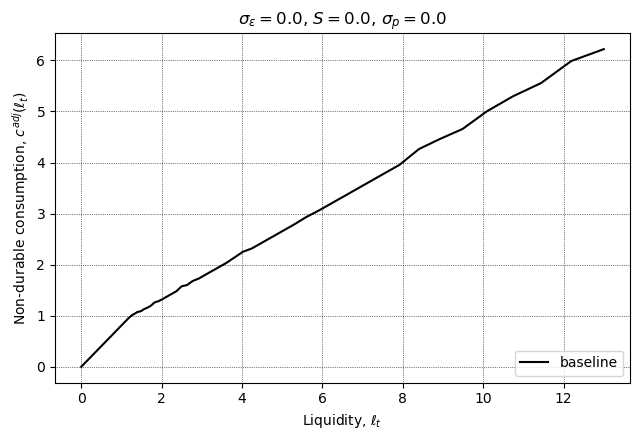

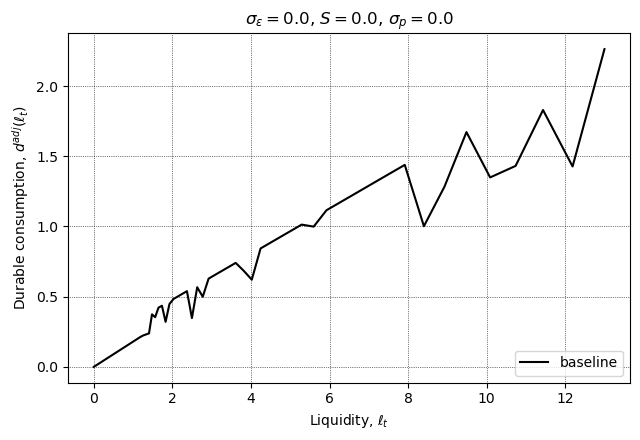

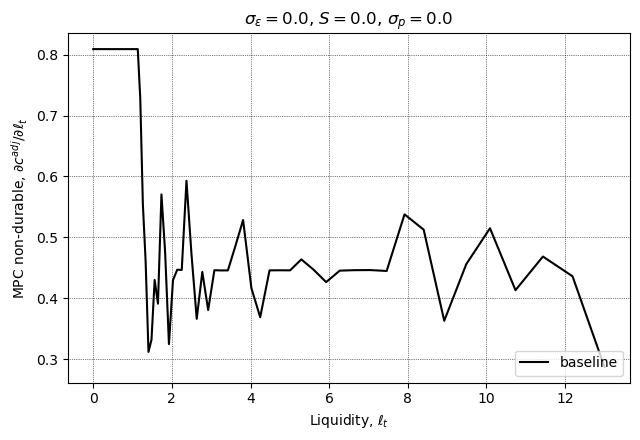

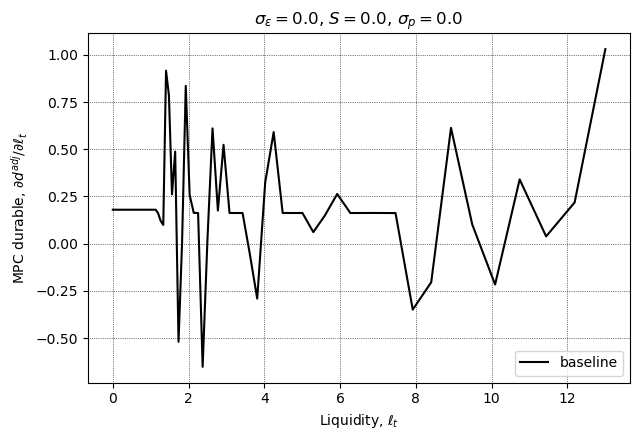

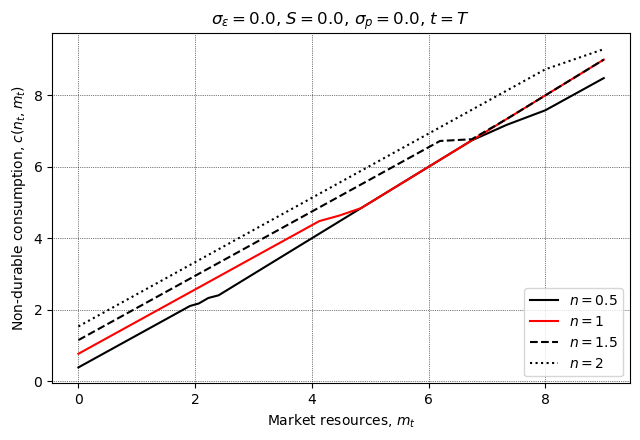

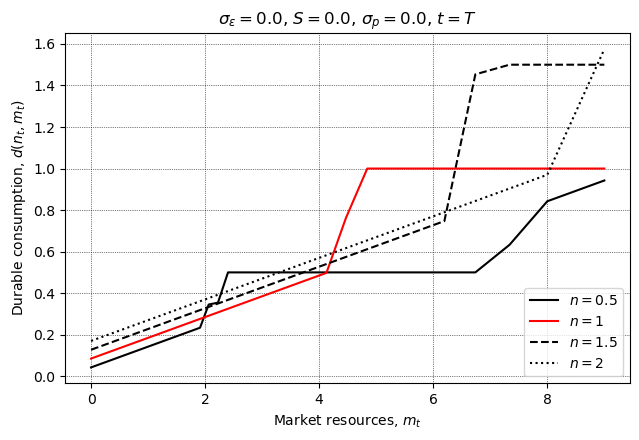

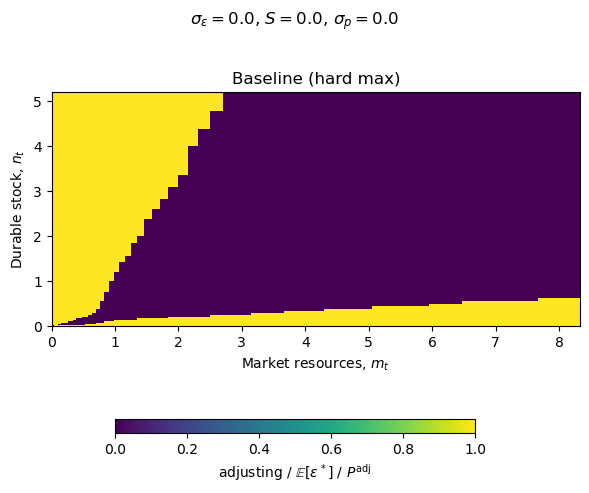

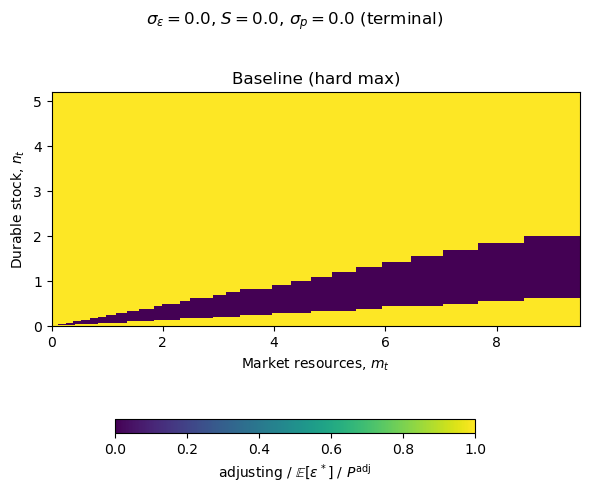

In [5]:
title = channel_title(0.0, 0.0, 0.0)
plot_adjuster_policies([Baseline], [r"baseline"], t, title, "Baseline")
plot_adjuster_mpcs([Baseline], [r"baseline"], t, title, "Baseline")
plot_combined_policies([Baseline], [r"baseline"], title, "Baseline")
plot_case_heatmaps(
    [Baseline],
    [r"Baseline (hard max)"],
    t,
    "Baseline",
    suptitle=title,
)



### Baseline-model (hard max; no EV taste, search, or price) with more shock points
- TranShkCount = 1, 7, 151
- TransitionMethod 

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

Solving TranShkCount=1 (expected)...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:465: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:472: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


Solving TranShkCount=7 (expected)...
Solving TranShkCount=151 (expected)...
Solving TransitionMethod...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:465: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:472: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


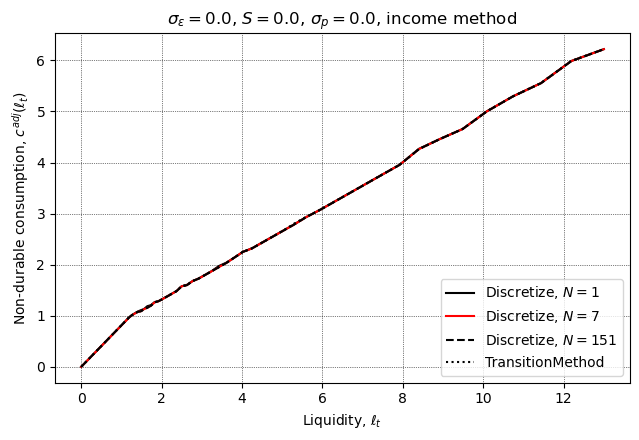

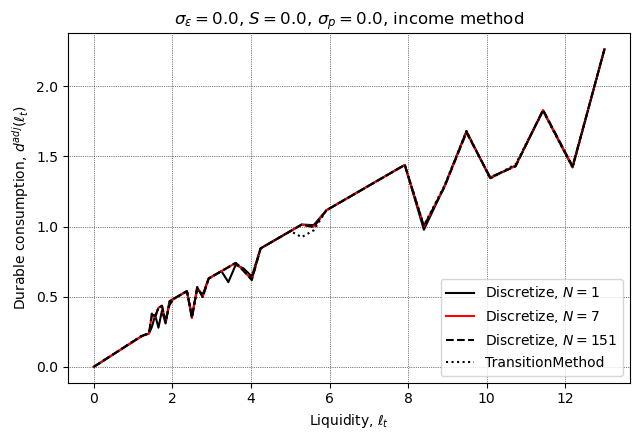

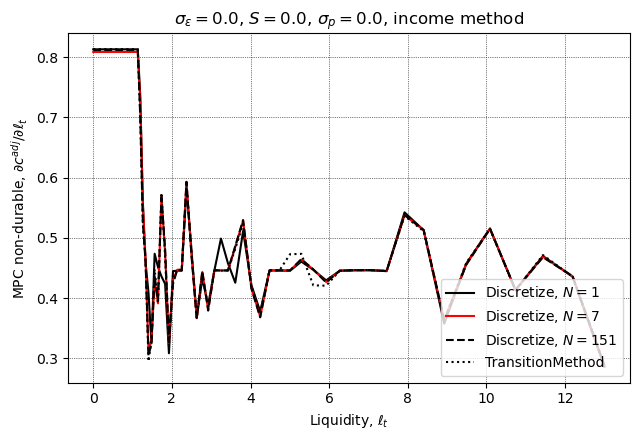

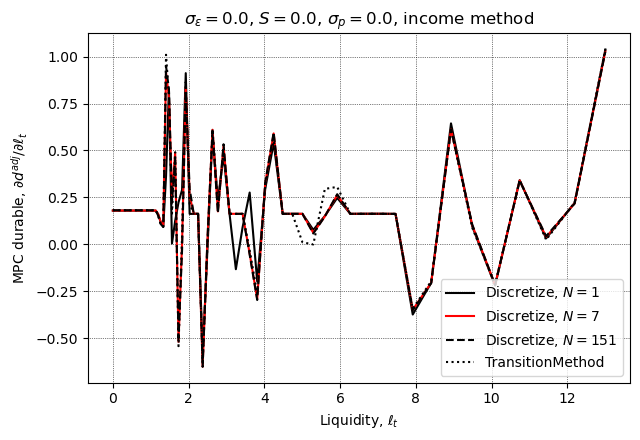

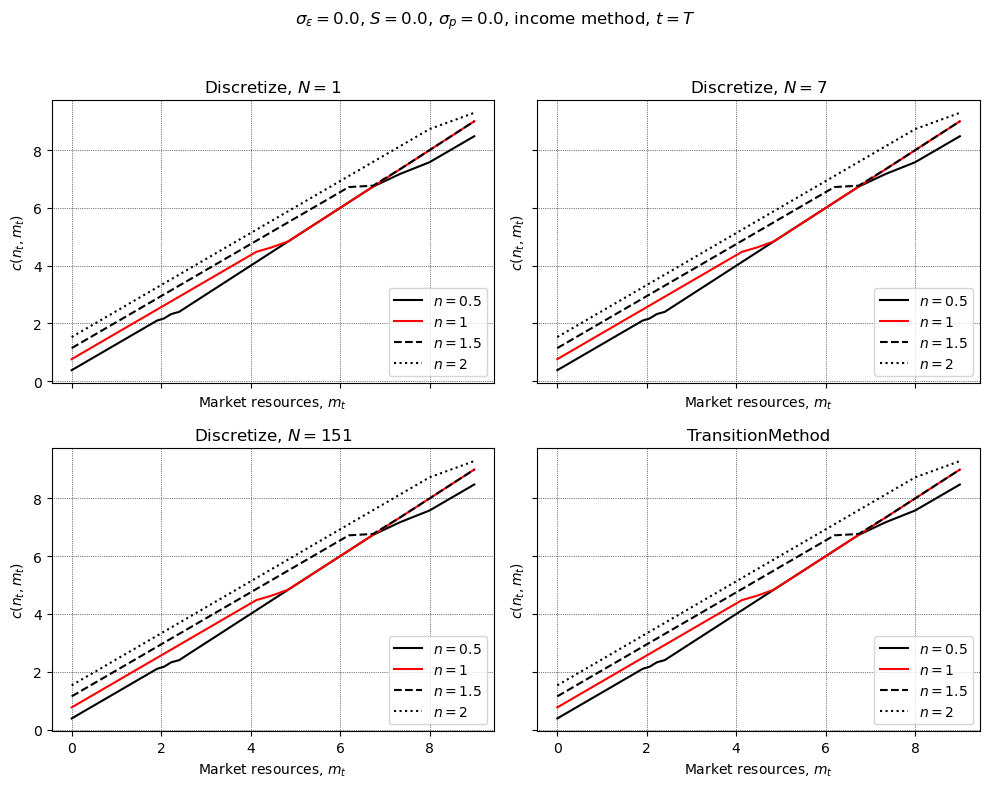

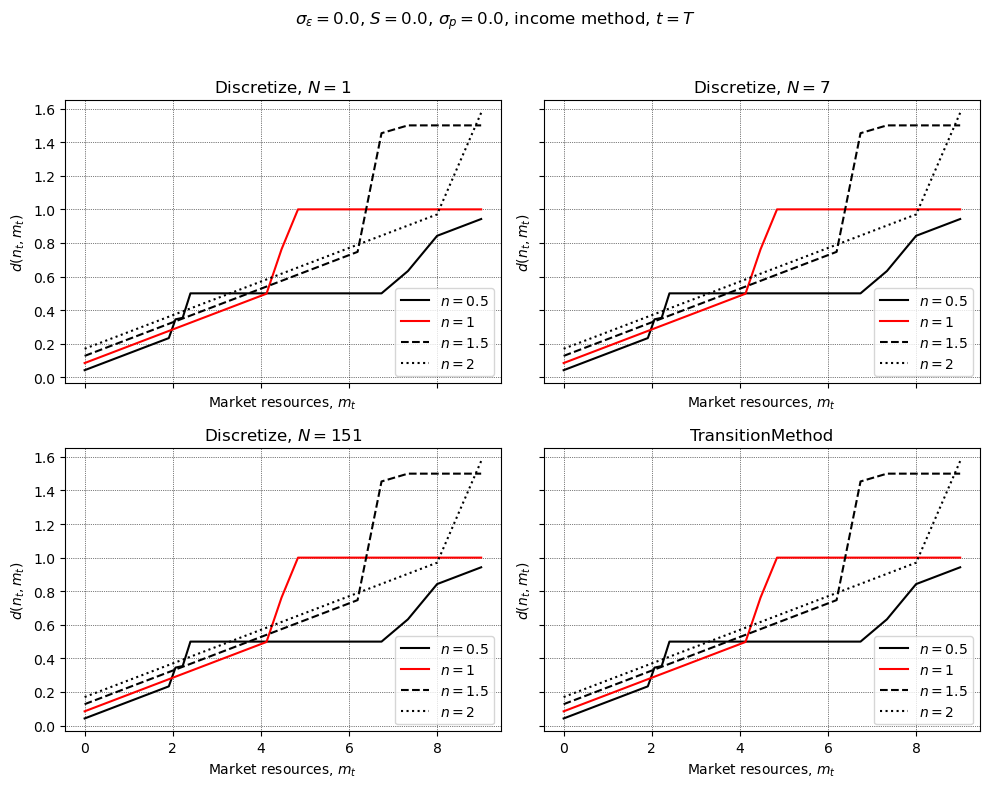

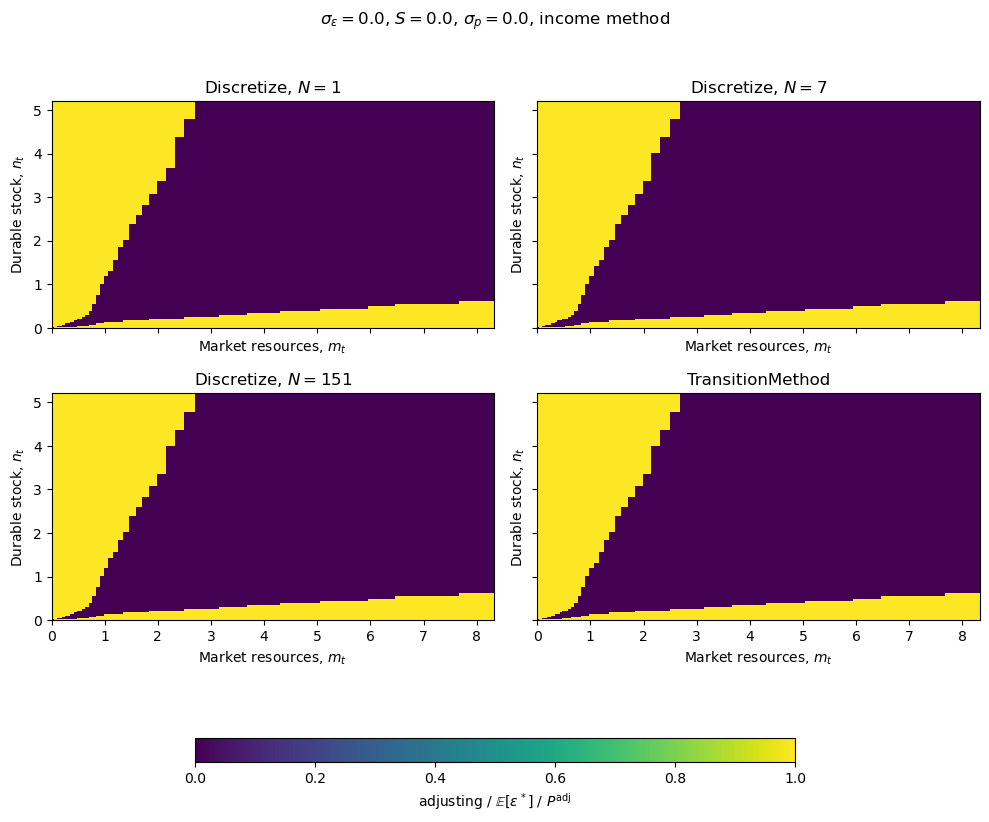

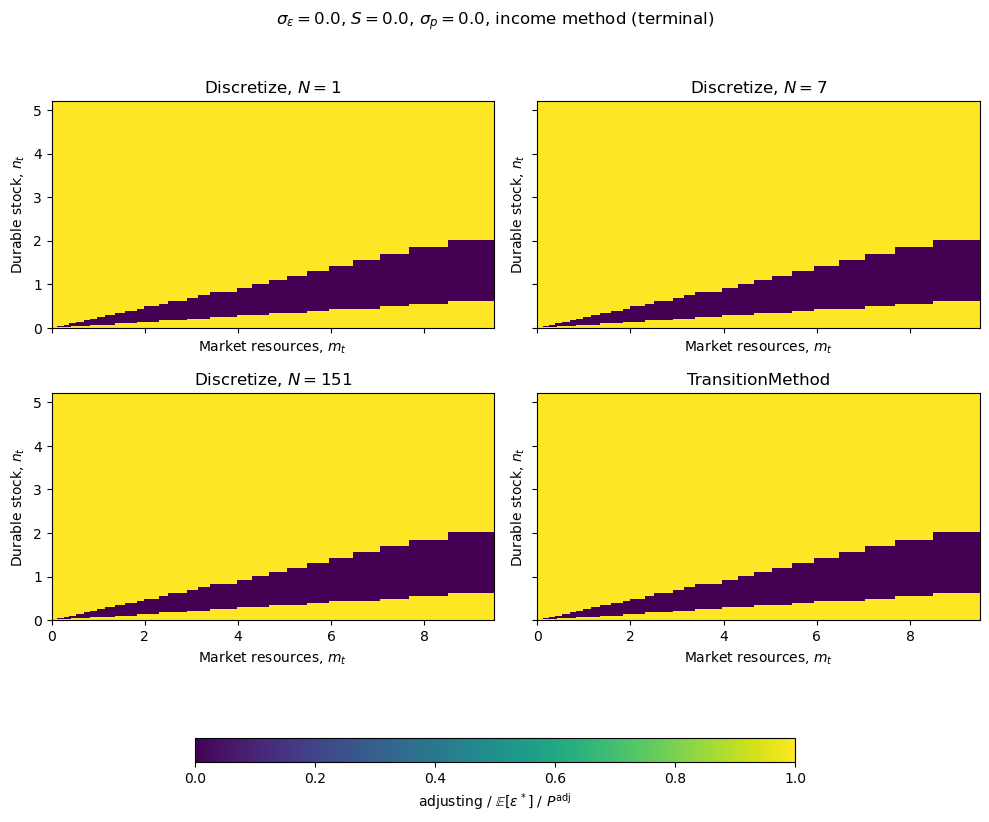

In [6]:
# Income discretization comparison (Figures_IncomeDiscMethod style):
# expected/Discretize with TranShkCount = 1, 7, 151 + TransitionMethod
base_inc = copy.deepcopy(durable_defaults)
base_inc["sigma_eps"] = 0.0
base_inc["SearchCost"] = 0.0
base_inc["PriceShkStd"] = 0.0
base_inc["PriceShkCount"] = 1

print("Solving TranShkCount=1 (expected)...")
Inc_1 = solve_variant(base_inc, TranShkCount=1, use_expected=True, use_TransitionMatrix=False)

print("Solving TranShkCount=7 (expected)...")
Inc_7 = solve_variant(base_inc, TranShkCount=7, use_expected=True, use_TransitionMatrix=False)

print("Solving TranShkCount=151 (expected)...")
Inc_151 = solve_variant(base_inc, TranShkCount=151, use_expected=True, use_TransitionMatrix=False)

print("Solving TransitionMethod...")
Inc_TM = solve_variant(
    base_inc,
    TranShkCount=7,
    use_expected=False,
    use_TransitionMatrix=True,
)

inc_models = [Inc_1, Inc_7, Inc_151, Inc_TM]
inc_labels = [
    r"Discretize, $N=1$",
    r"Discretize, $N=7$",
    r"Discretize, $N=151$",
    r"TransitionMethod",
]
inc_panels = [
    r"Discretize, $N=1$",
    r"Discretize, $N=7$",
    r"Discretize, $N=151$",
    r"TransitionMethod",
]

title = channel_title(0.0, 0.0, 0.0, extra=r"income method")
plot_adjuster_policies(inc_models, inc_labels, t, title, "IncomeDisc")
plot_adjuster_mpcs(inc_models, inc_labels, t, title, "IncomeDisc")
plot_combined_policies(inc_models, inc_labels, title, "IncomeDisc")
plot_case_heatmaps(inc_models, inc_panels, t, "IncomeDisc", suptitle=title)



### TasteShockModel (EV Type I; no search, no price)
- EV Type I taste scale $\sigma_\varepsilon \in \{0, 0.05, 0.1, 0.2\}$

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

Solving taste sigma_eps=0.0...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:465: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:472: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


Solving taste sigma_eps=0.05...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:184: RuntimeWarning: divide by zero encountered in power
  return uP ** (-1.0 / rho)


Solving taste sigma_eps=0.1...
Solving taste sigma_eps=0.2...


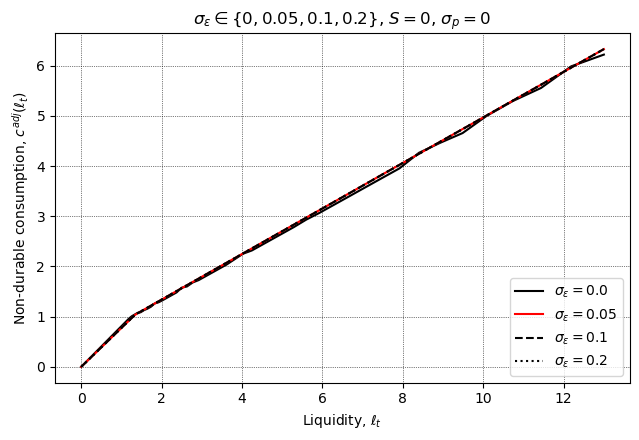

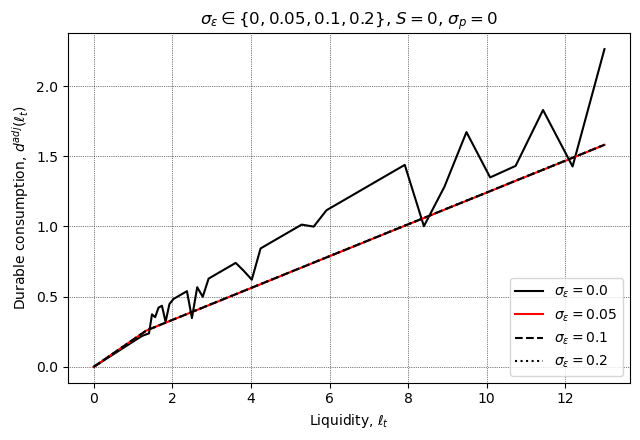

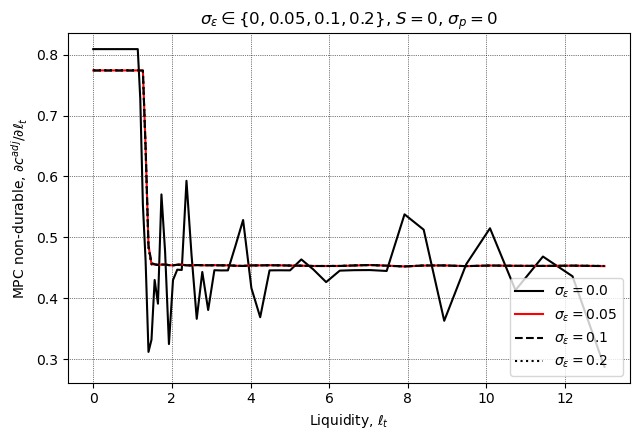

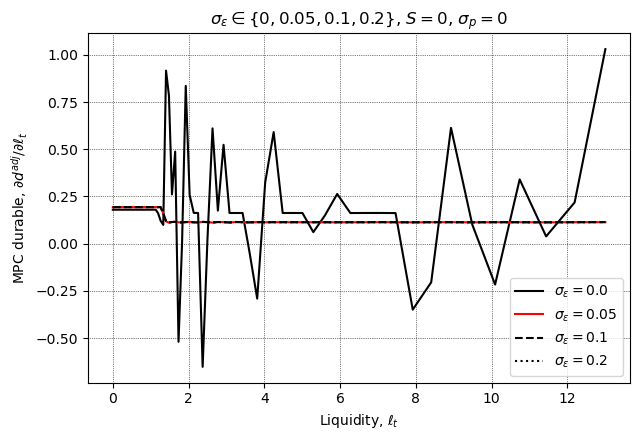

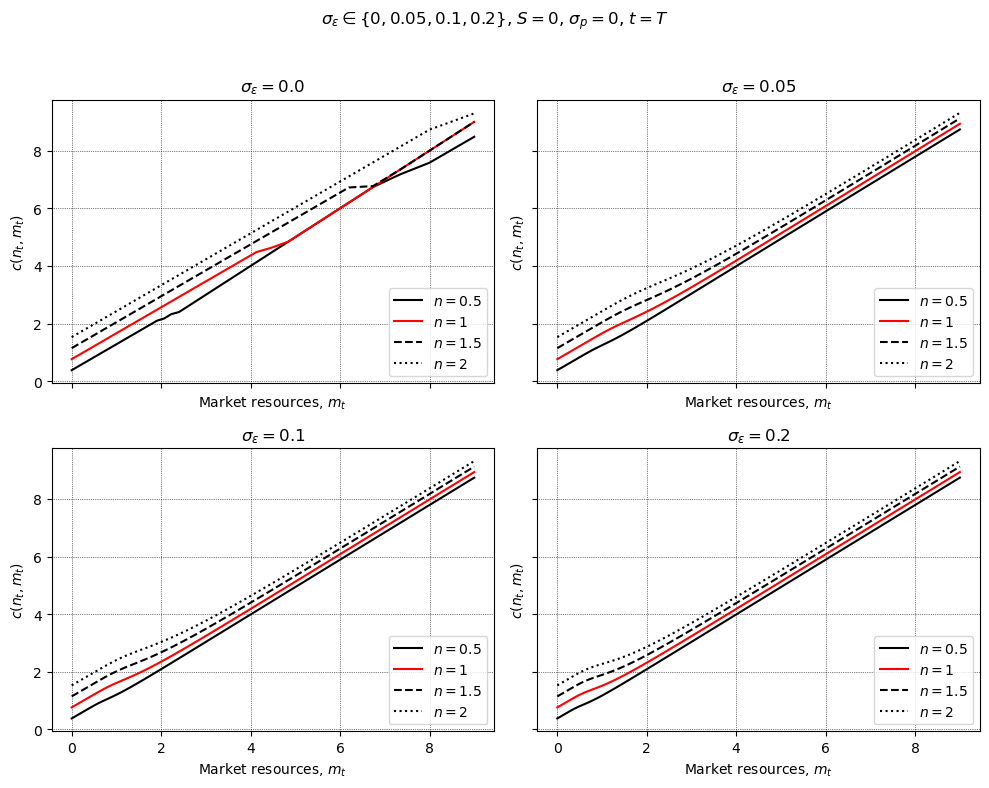

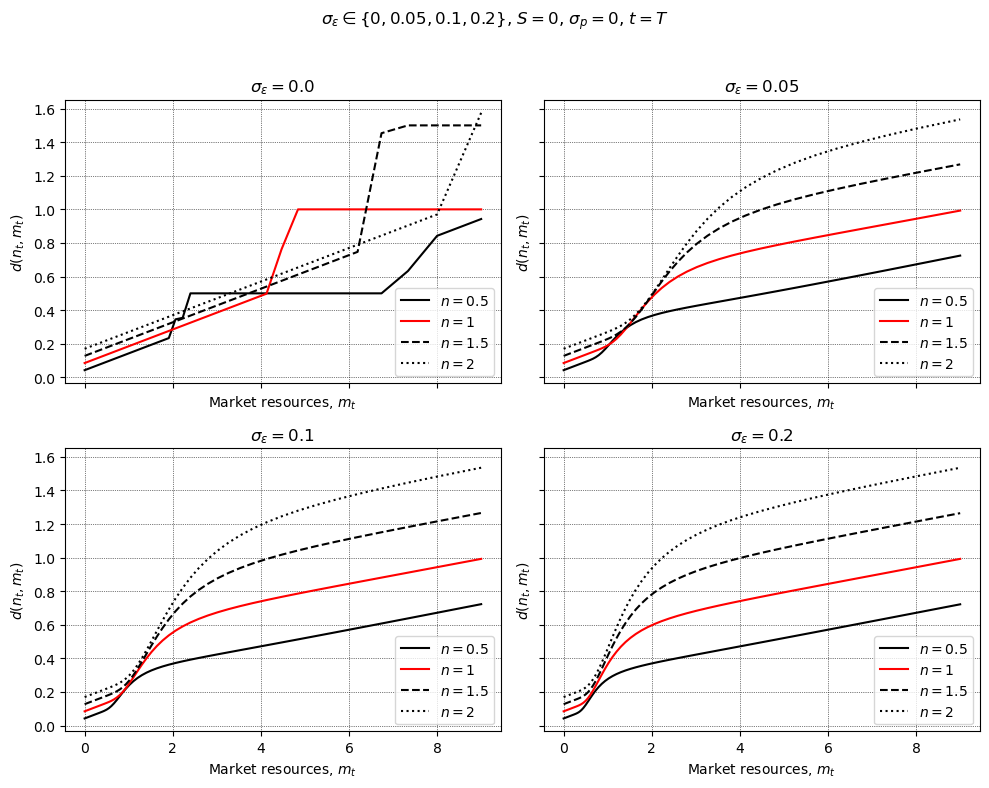

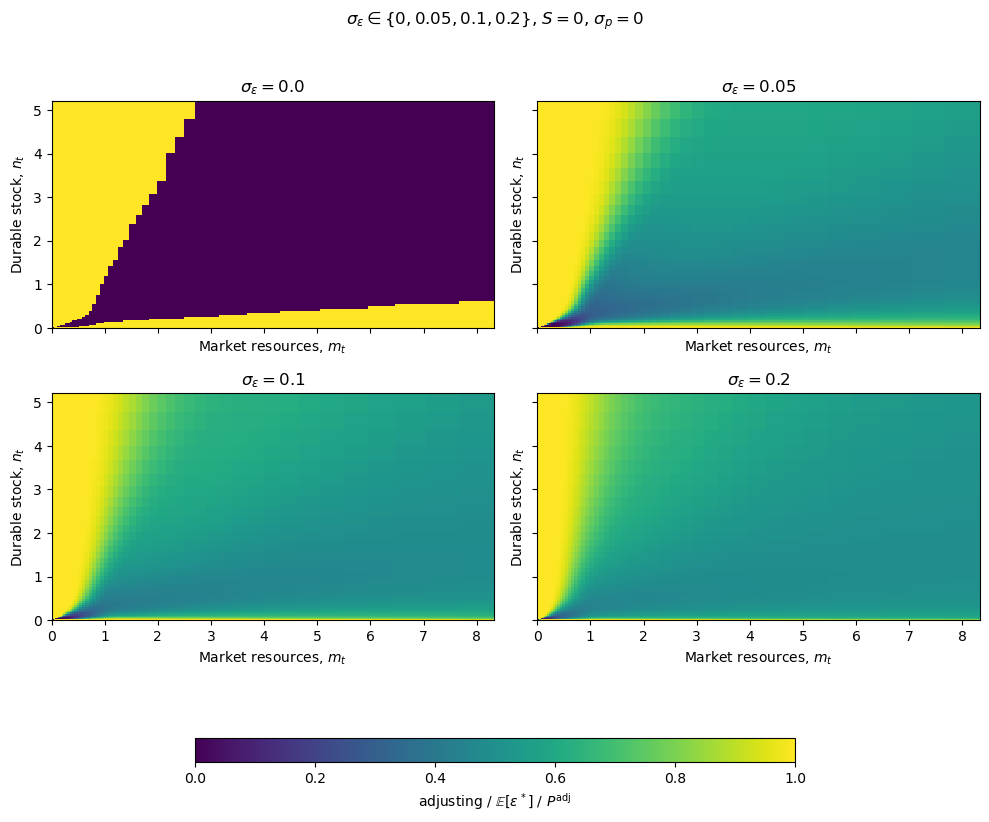

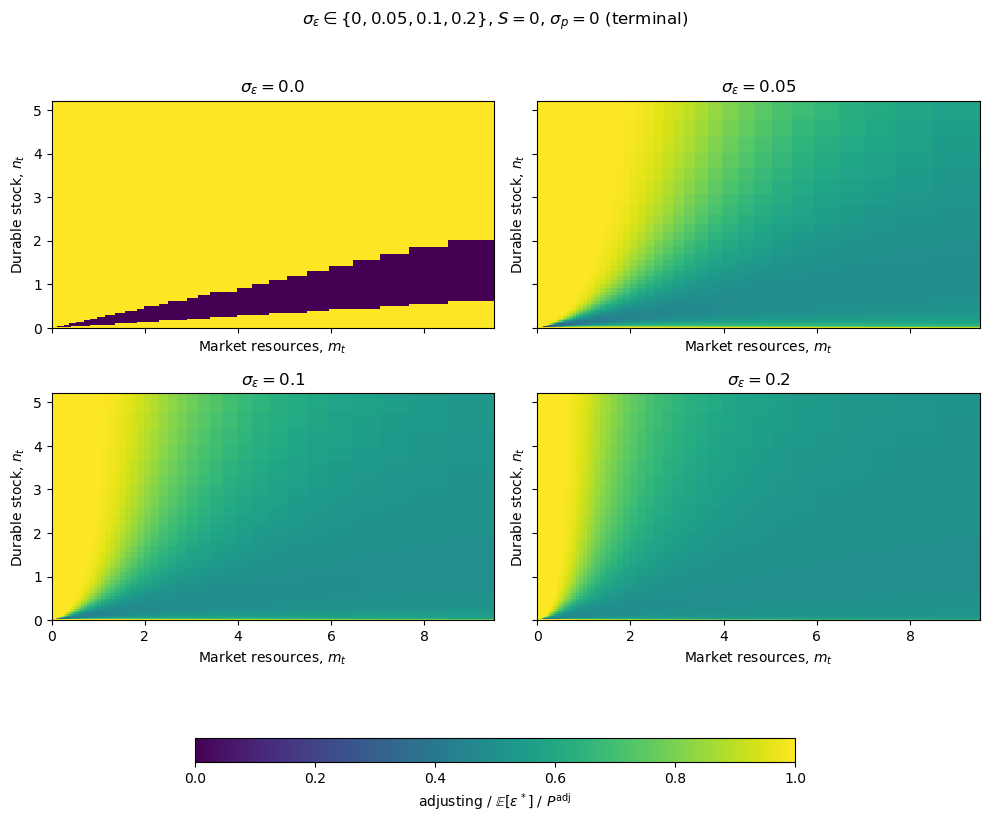

In [7]:
base_taste = copy.deepcopy(durable_defaults)
base_taste["SearchCost"] = 0.0
base_taste["PriceShkStd"] = 0.0
base_taste["PriceShkCount"] = 1

sigmas = [0.0, 0.05, 0.1, 0.2]
taste_models = []
for sx in sigmas:
    print(f"Solving taste sigma_eps={sx}...")
    taste_models.append(
        solve_variant(
            base_taste,
            sigma_eps=sx,
        )
    )

taste_labels = [rf"$\sigma_{{\varepsilon}} = {sx}$" for sx in sigmas]
taste_panels = taste_labels
title = r"$\sigma_{\varepsilon} \in \{0, 0.05, 0.1, 0.2\}$, $S = 0$, $\sigma_{p} = 0$"
plot_adjuster_policies(taste_models, taste_labels, t, title, "TasteShock")
plot_adjuster_mpcs(taste_models, taste_labels, t, title, "TasteShock")
plot_combined_policies(taste_models, taste_labels, title, "TasteShock")
plot_case_heatmaps(taste_models, taste_panels, t, "TasteShock", suptitle=title)



### SearchModel (no EV taste, no price)
- Search = 0, 0.05, 0.1, 0.2

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

Solving SearchCost=0.0...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:465: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:472: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


Solving SearchCost=0.05...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:472: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:465: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\utility.py:541: RuntimeWarning: divide by zero encountered in power
  return shocks[0] ** (-CRRA) * (


Solving SearchCost=0.1...
Solving SearchCost=0.2...


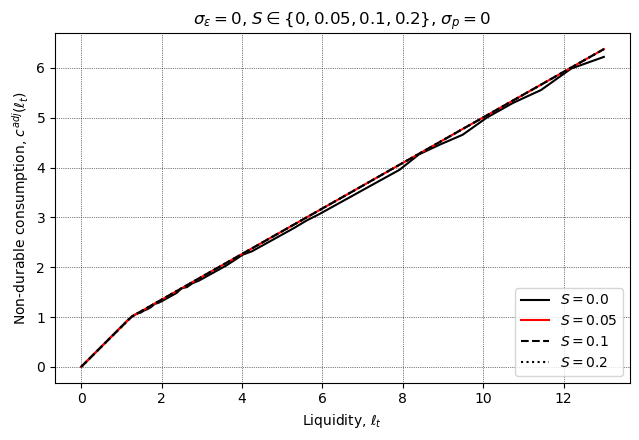

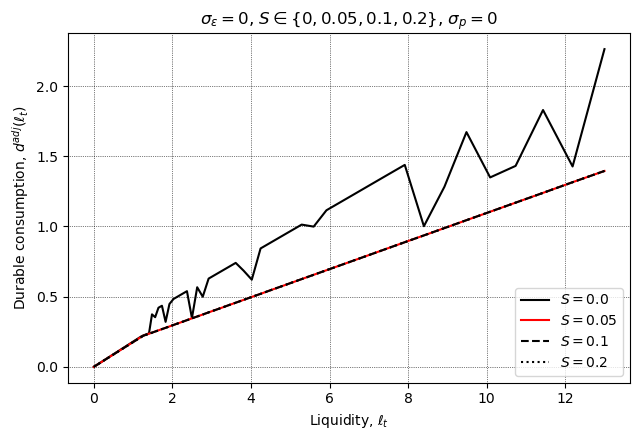

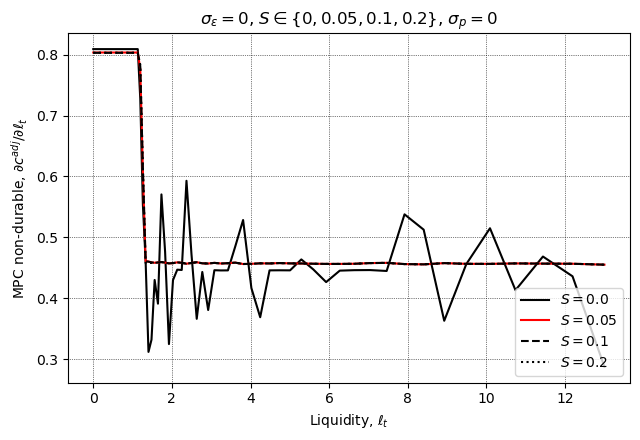

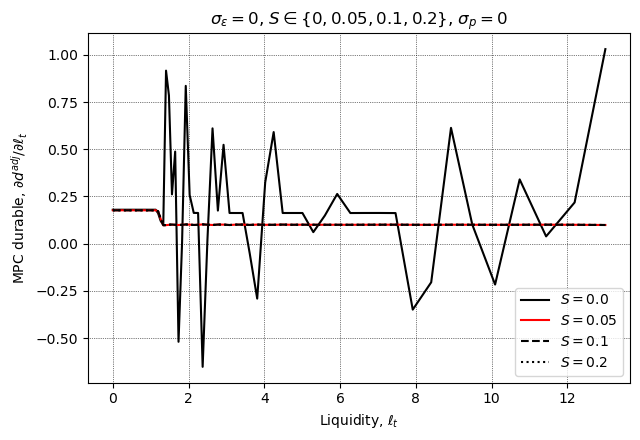

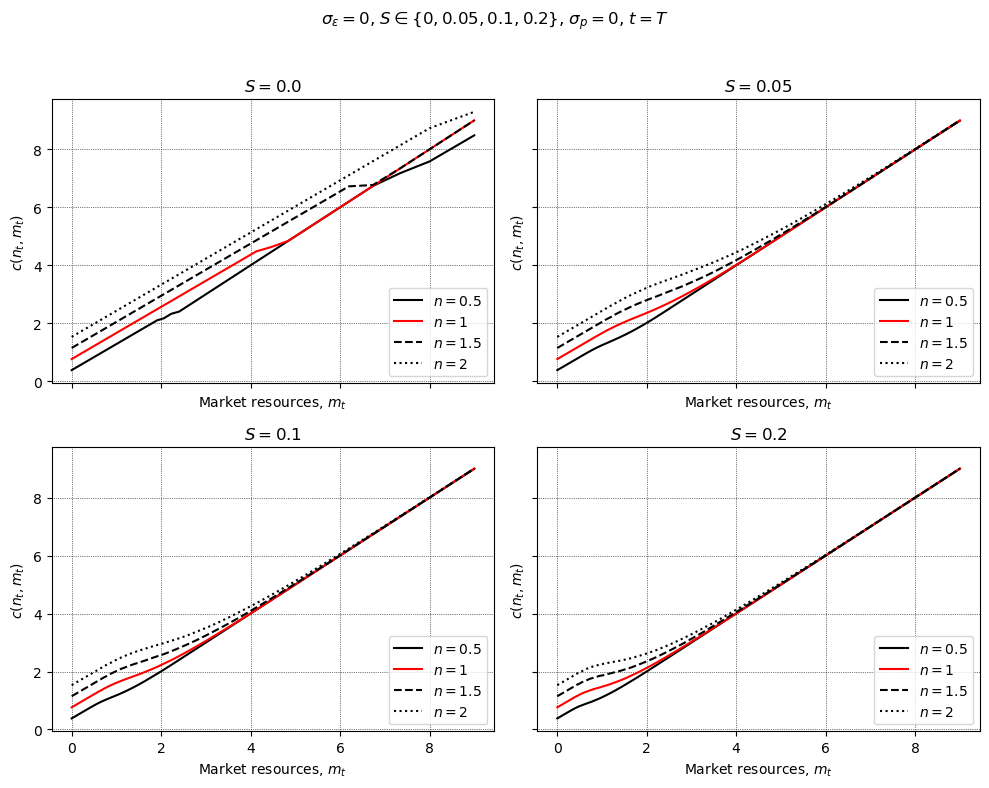

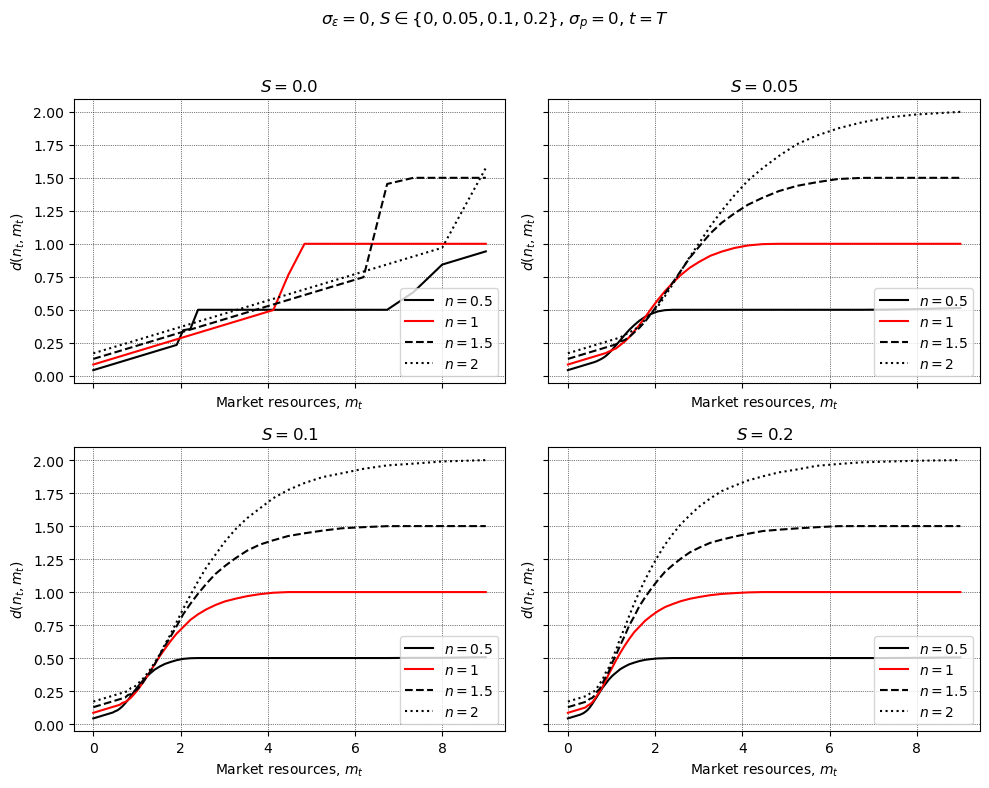

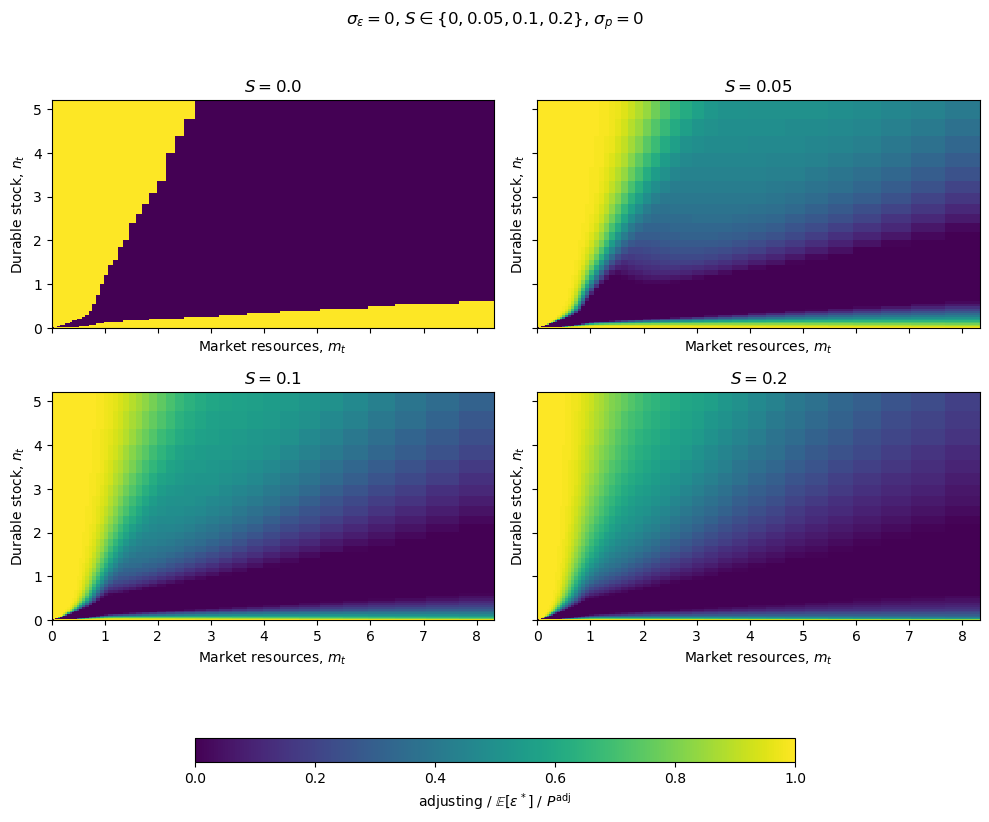

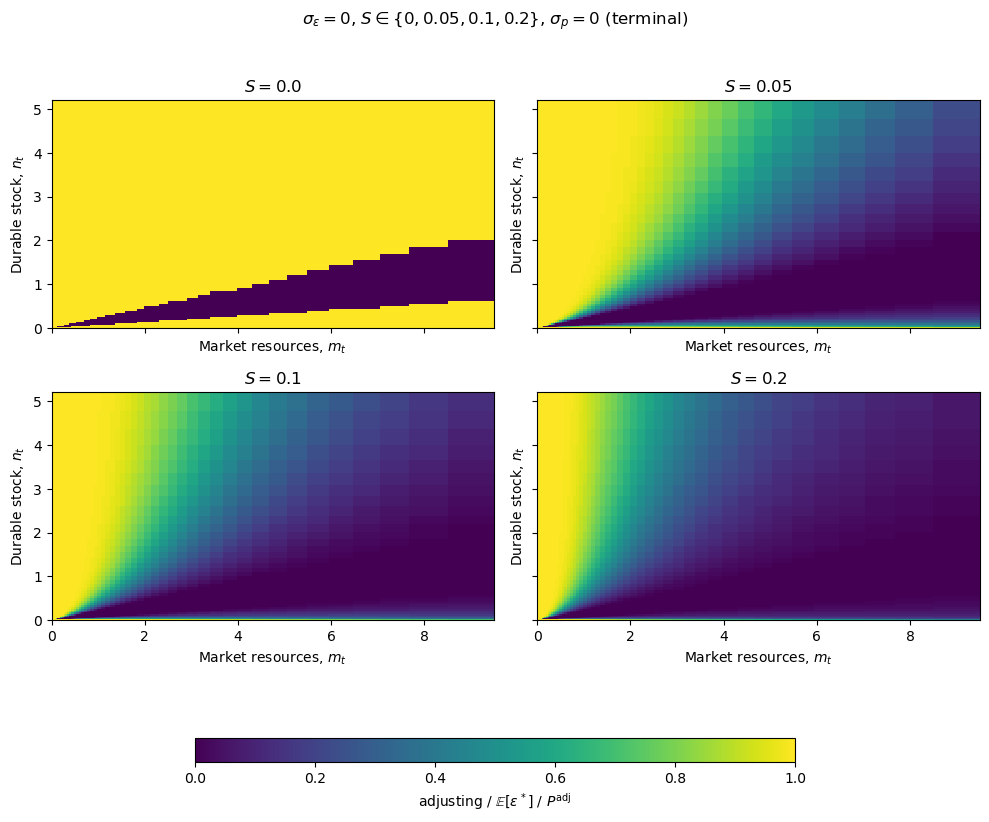

In [8]:
base_search = copy.deepcopy(durable_defaults)
base_search["sigma_eps"] = 0.0
base_search["PriceShkStd"] = 0.0
base_search["PriceShkCount"] = 1

S_vals = [0.0, 0.05, 0.1, 0.2]
search_models = []
for S in S_vals:
    print(f"Solving SearchCost={S}...")
    search_models.append(solve_variant(base_search, SearchCost=S))

search_labels = [rf"$S = {S}$" for S in S_vals]
title = r"$\sigma_{\varepsilon} = 0$, $S \in \{0, 0.05, 0.1, 0.2\}$, $\sigma_{p} = 0$"
plot_adjuster_policies(search_models, search_labels, t, title, "Search")
plot_adjuster_mpcs(search_models, search_labels, t, title, "Search")
plot_combined_policies(search_models, search_labels, title, "Search")
plot_case_heatmaps(search_models, search_labels, t, "Search", suptitle=title)



### PriceModel (no EV taste, no search)
- Price standard deviation = 0, 0.05, 0.1, 0.2

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

Solving PriceShkStd=0.0...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:465: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:472: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


Solving PriceShkStd=0.05...
Solving PriceShkStd=0.1...
Solving PriceShkStd=0.2...


c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\utility.py:541: RuntimeWarning: divide by zero encountered in power
  return shocks[0] ** (-CRRA) * (


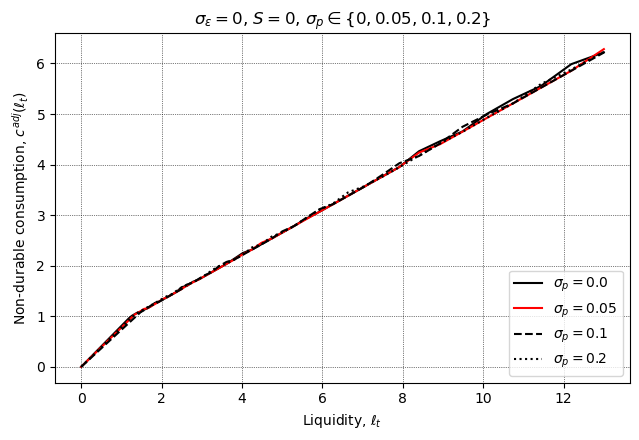

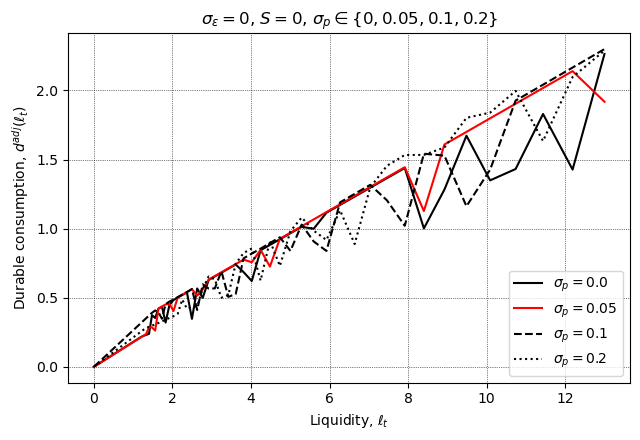

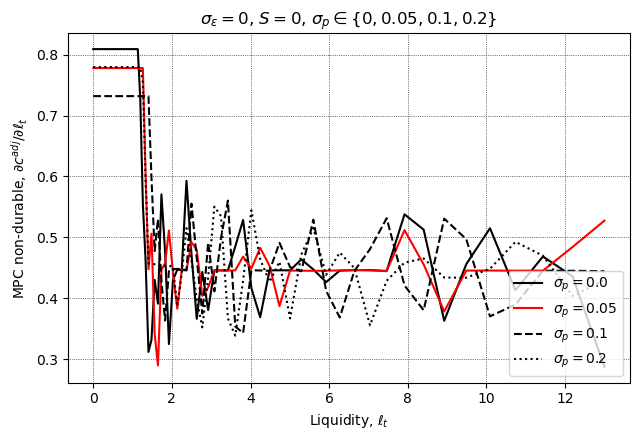

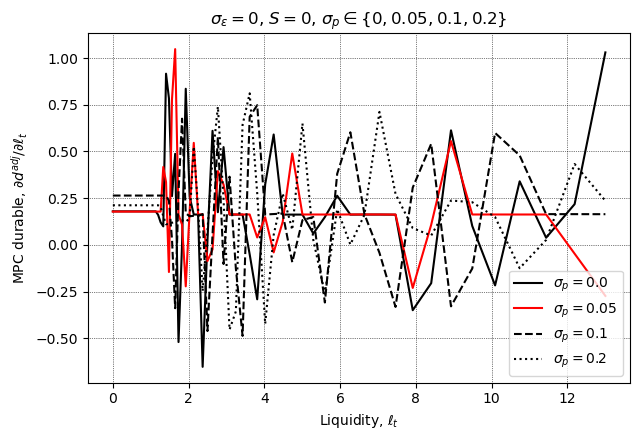

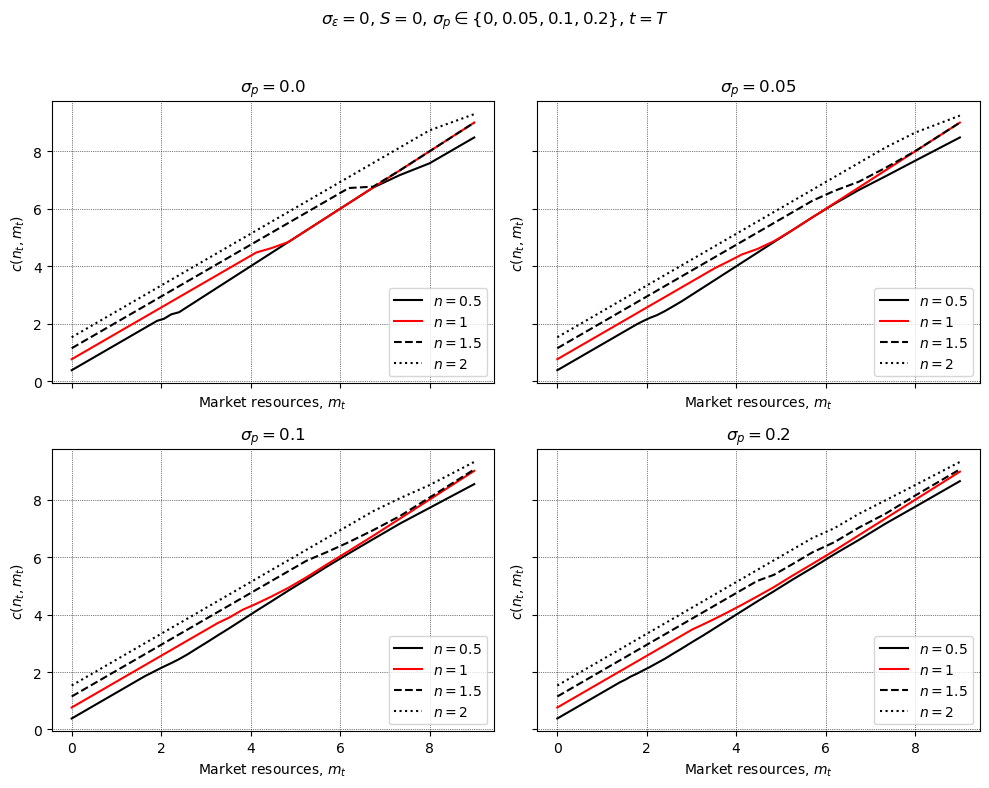

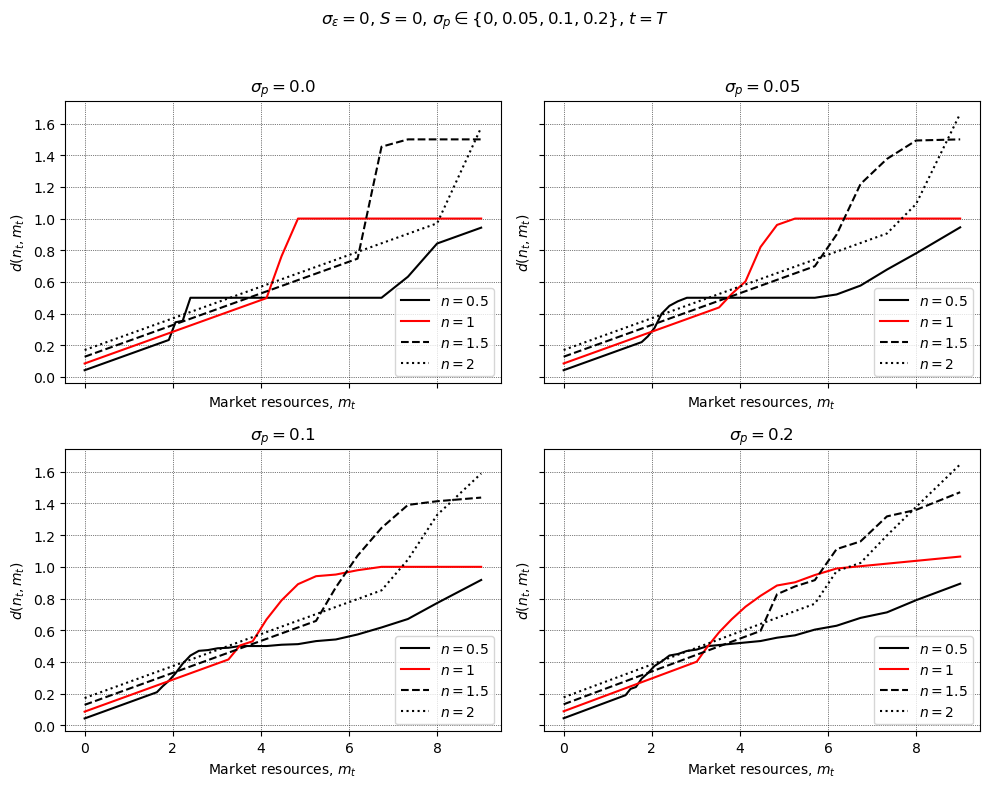

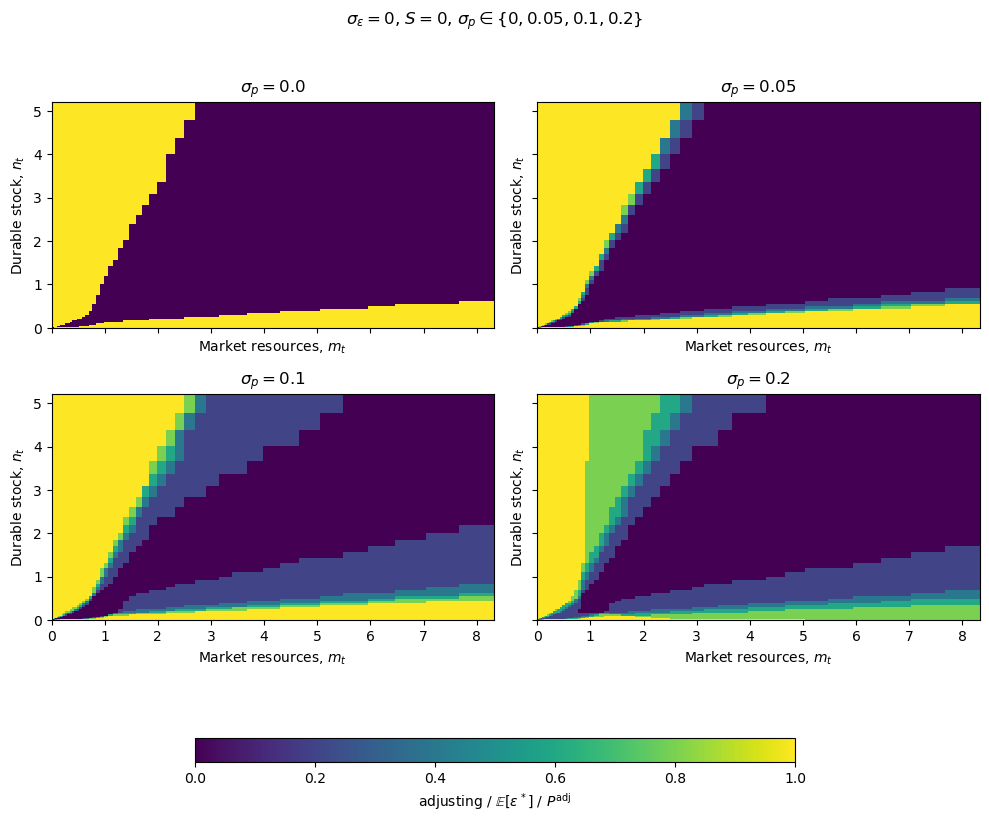

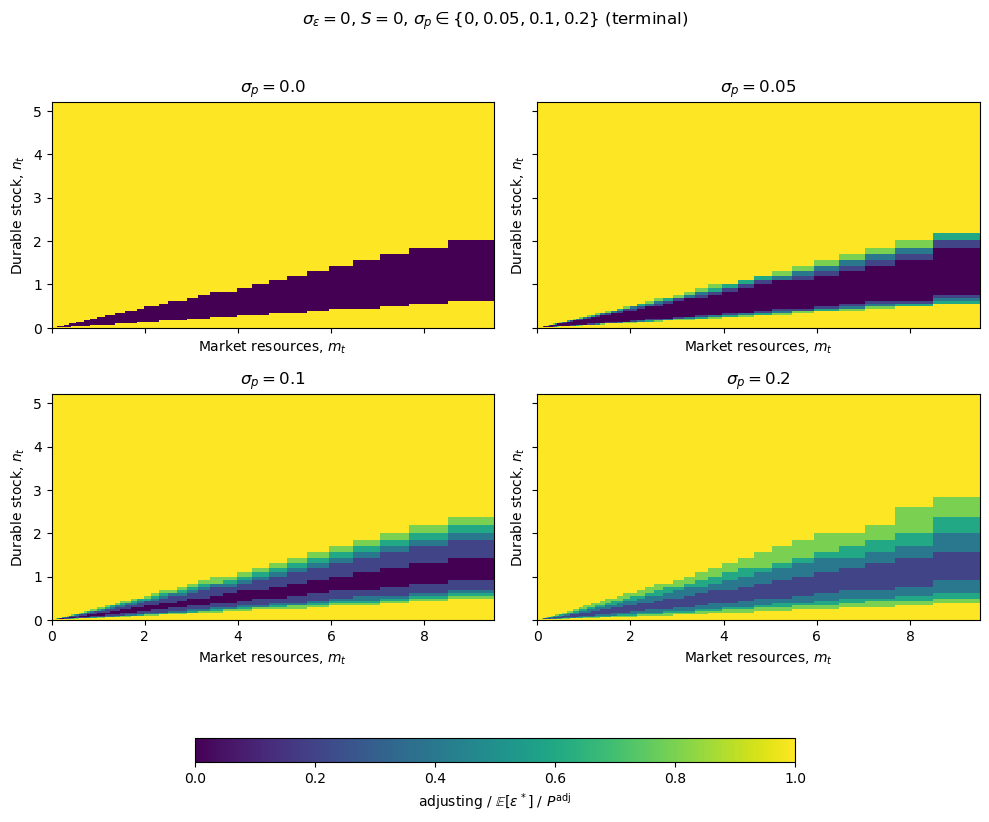

In [9]:
base_price = copy.deepcopy(durable_defaults)
base_price["sigma_eps"] = 0.0
base_price["SearchCost"] = 0.0

p_stds = [0.0, 0.05, 0.1, 0.2]
price_models = []
for ps in p_stds:
    print(f"Solving PriceShkStd={ps}...")
    price_models.append(
        solve_variant(
            base_price,
            PriceShkStd=ps,
            PriceShkCount=1 if ps == 0.0 else base_price["PriceShkCount"],
        )
    )

price_labels = [rf"$\sigma_{{p}} = {ps}$" for ps in p_stds]
title = r"$\sigma_{\varepsilon} = 0$, $S = 0$, $\sigma_{p} \in \{0, 0.05, 0.1, 0.2\}$"
plot_adjuster_policies(price_models, price_labels, t, title, "PriceStd")
plot_adjuster_mpcs(price_models, price_labels, t, title, "PriceStd")
plot_combined_policies(price_models, price_labels, title, "PriceStd")
plot_case_heatmaps(price_models, price_labels, t, "PriceStd", suptitle=title)



### Price (no EV taste, no search): varying PriceShkCount
- Price standard deviation = 0.1
- Price shock points = 1, 5, 13, 21

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

Solving PriceShkCount=1...


c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:465: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:472: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))


Solving PriceShkCount=5...
Solving PriceShkCount=13...
Solving PriceShkCount=21...


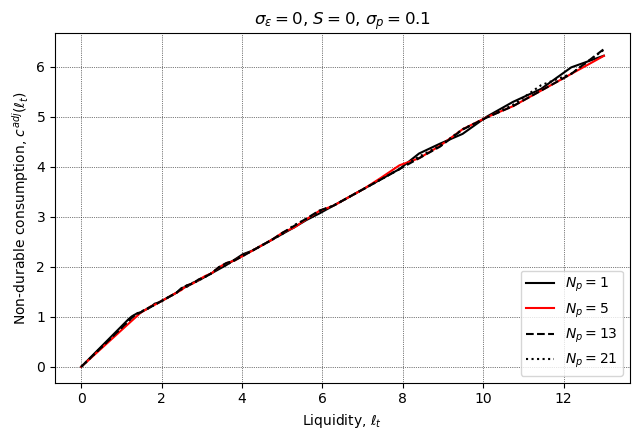

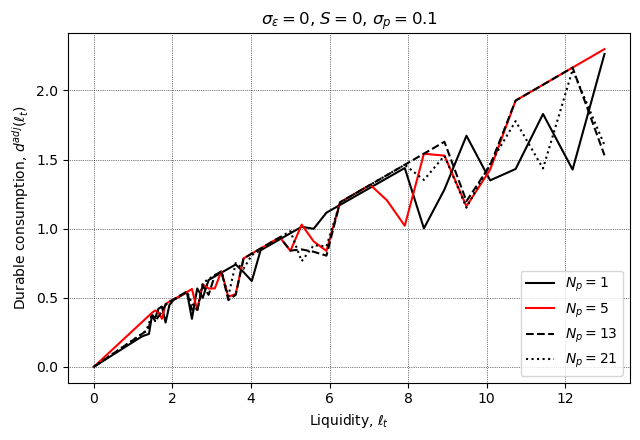

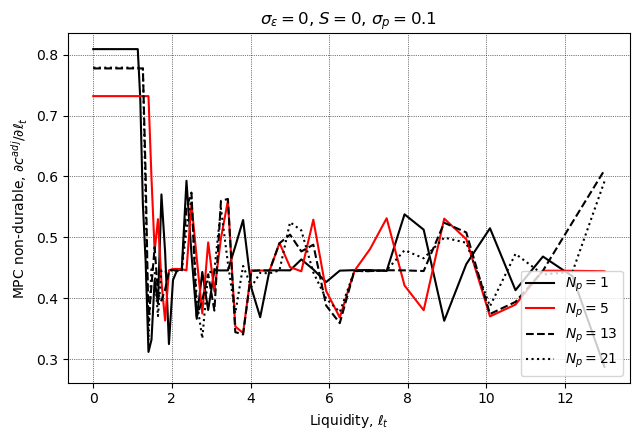

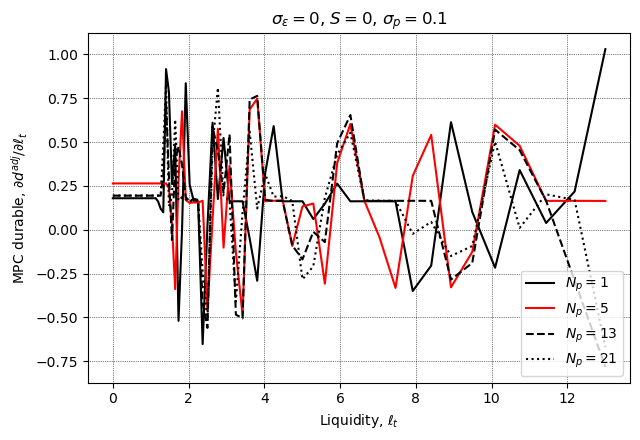

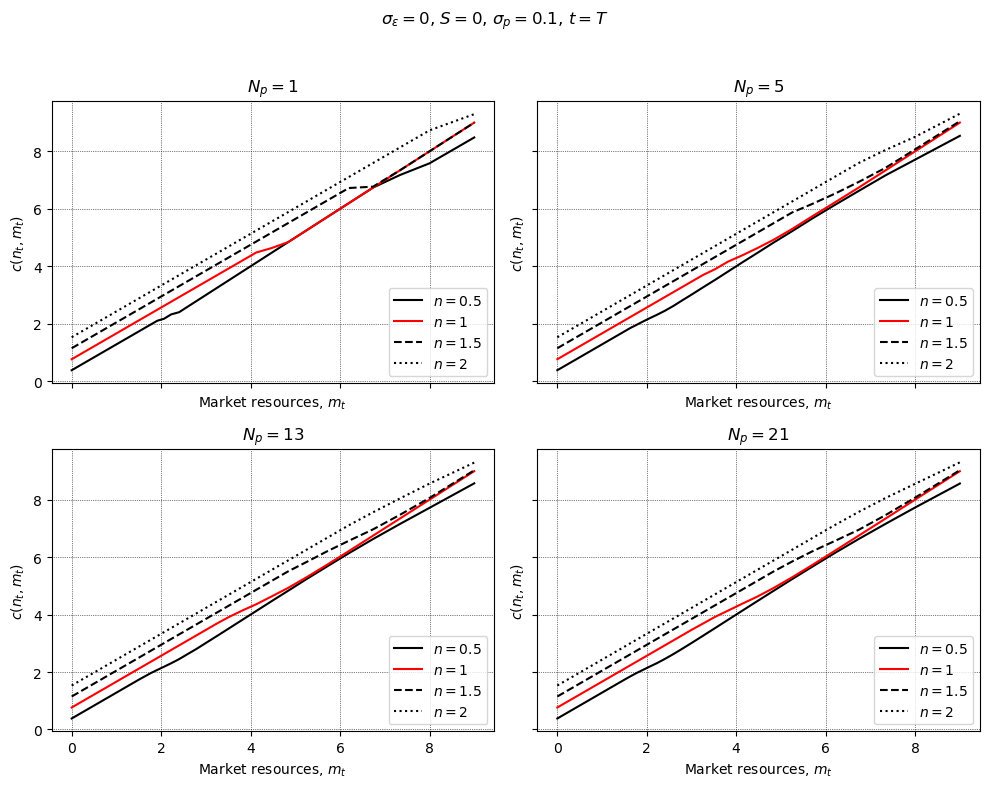

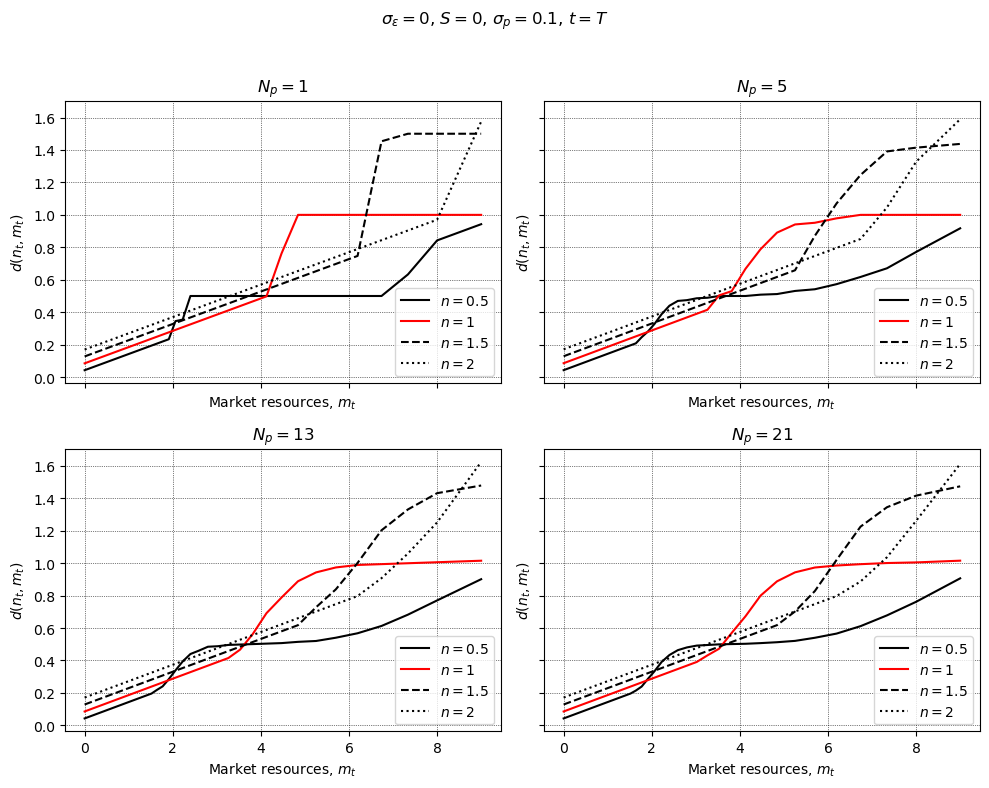

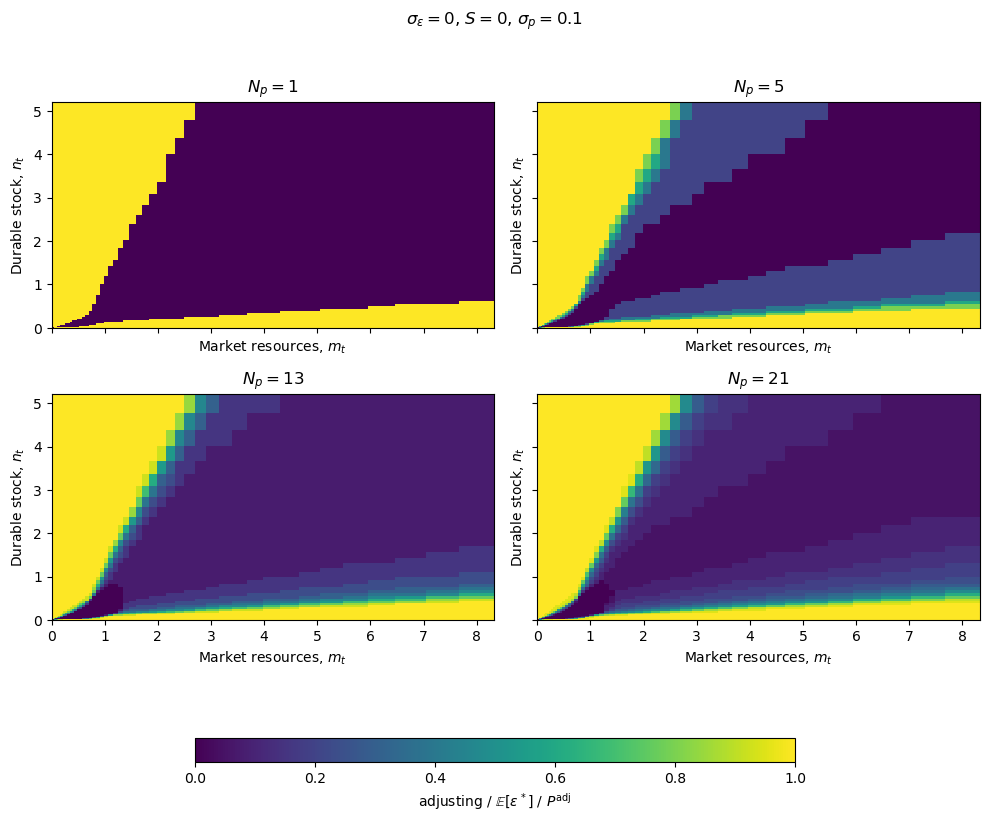

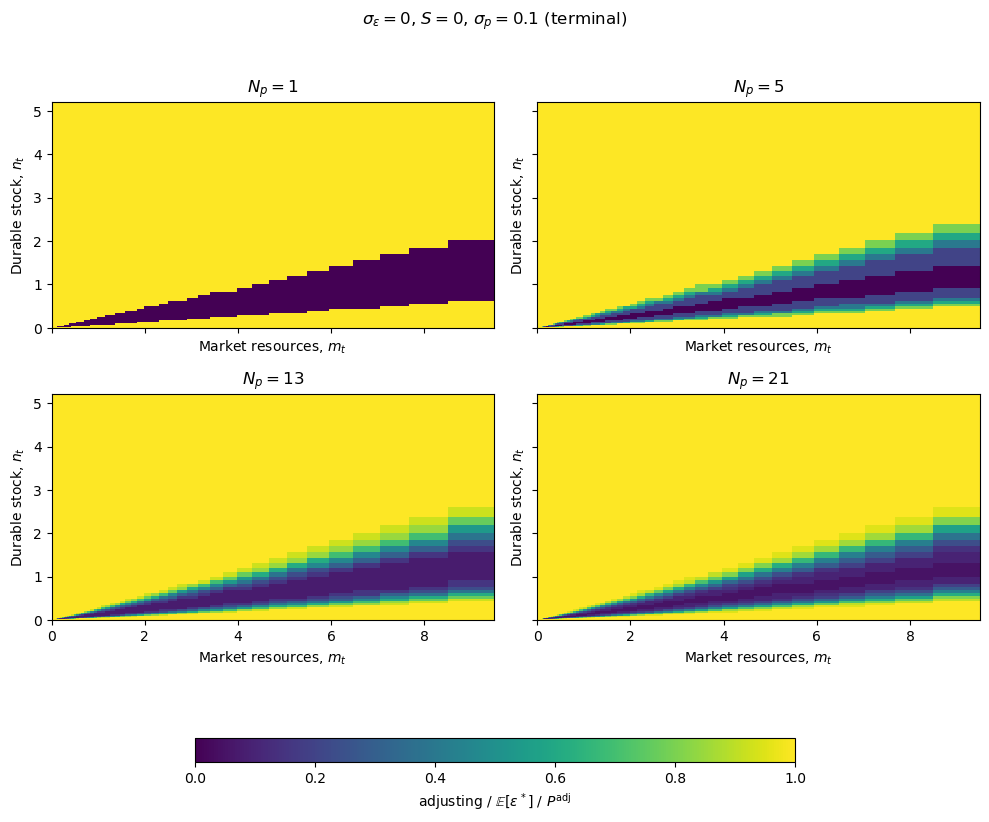

All durable figures done in 0:01:28.193139
Saved under C:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Figures\DurableModel


In [10]:
base_pcount = copy.deepcopy(durable_defaults)
base_pcount["sigma_eps"] = 0.0
base_pcount["SearchCost"] = 0.0
base_pcount["PriceShkStd"] = 0.1

p_counts = [1, 5, 13, 21]
pcount_models = []
for nc in p_counts:
    print(f"Solving PriceShkCount={nc}...")
    pcount_models.append(solve_variant(base_pcount, PriceShkCount=nc))

pcount_labels = [rf"$N_p = {nc}$" for nc in p_counts]
title = r"$\sigma_{\varepsilon} = 0$, $S = 0$, $\sigma_{p} = 0.1$"
plot_adjuster_policies(pcount_models, pcount_labels, t, title, "PriceCount")
plot_adjuster_mpcs(pcount_models, pcount_labels, t, title, "PriceCount")
plot_combined_policies(pcount_models, pcount_labels, title, "PriceCount")
plot_case_heatmaps(pcount_models, pcount_labels, t, "PriceCount", suptitle=title)

elapsed = time.time() - start_time
print("All durable figures done in", str(datetime.timedelta(seconds=elapsed)))
print("Saved under", FIG_DIR.resolve())



### Price and Search Model (Combined; no EV taste)
- Price standard deviation = 0, 0.1
- Search = 0, 0.1

Plot:
- non-durable consumption function of adjuster (all 4 in one)
- durable consumption function of the adjuster (all 4 in one)
- Ss structure (similar to DurableModel_One_Period.ipynb) (4 subplots)

c:\Users\adria\anaconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:465: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\DurableModel.py:472: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\adria\OneDrive - Johns Hopkins\Github\AMonninger\DCEGM_Search\Code\utility.py:541: RuntimeWarning: divide by zero encountered in power
  return shocks[0] ** (-CRRA) * (


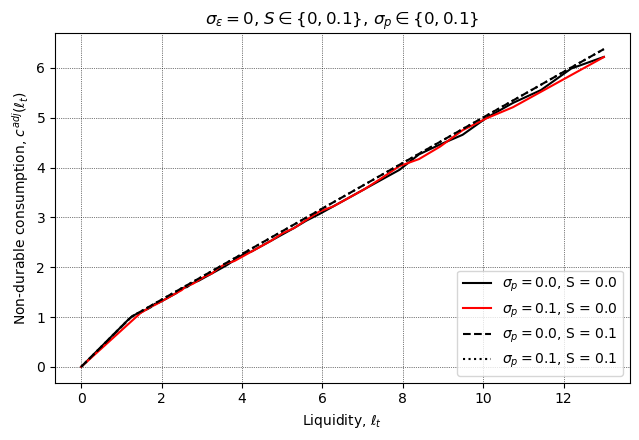

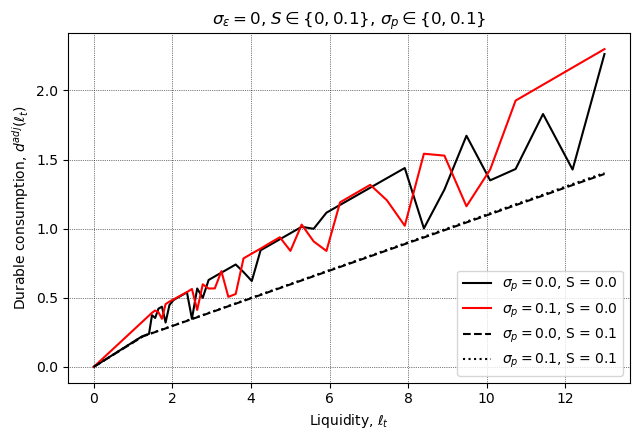

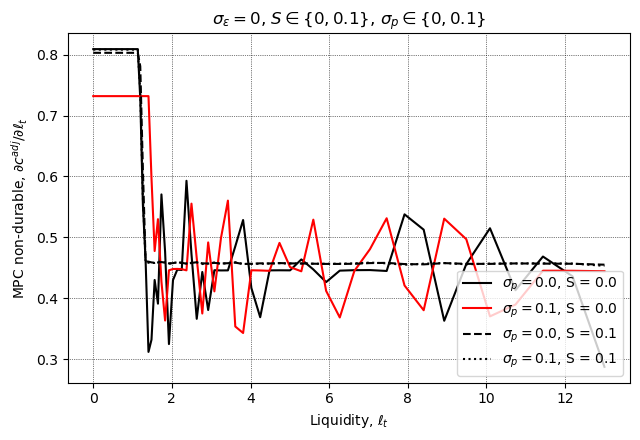

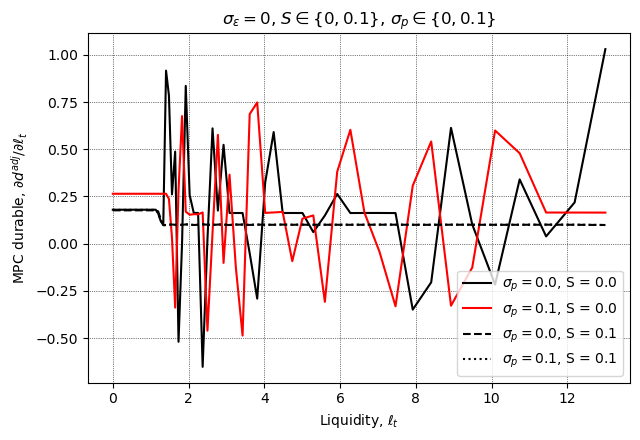

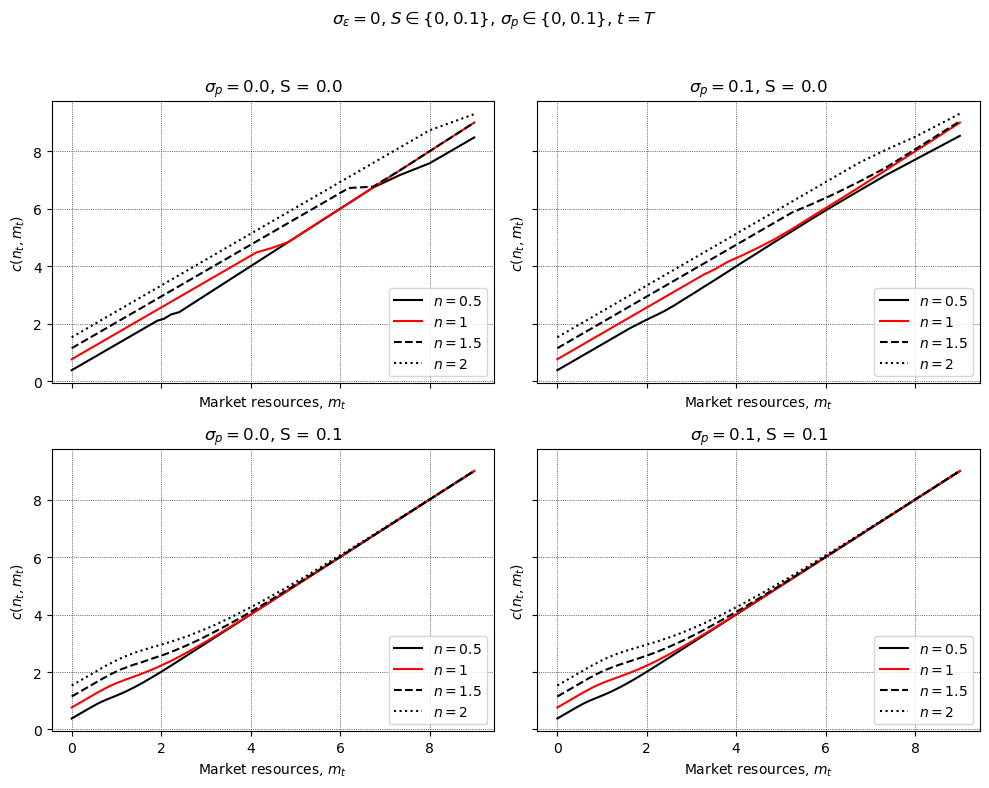

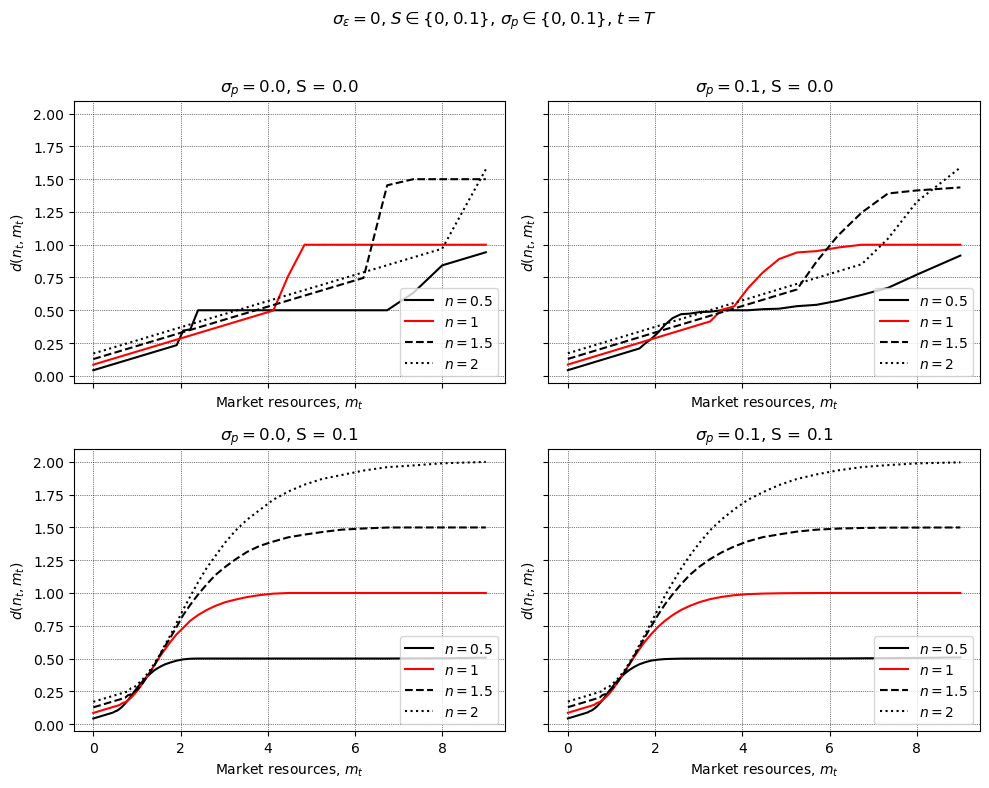

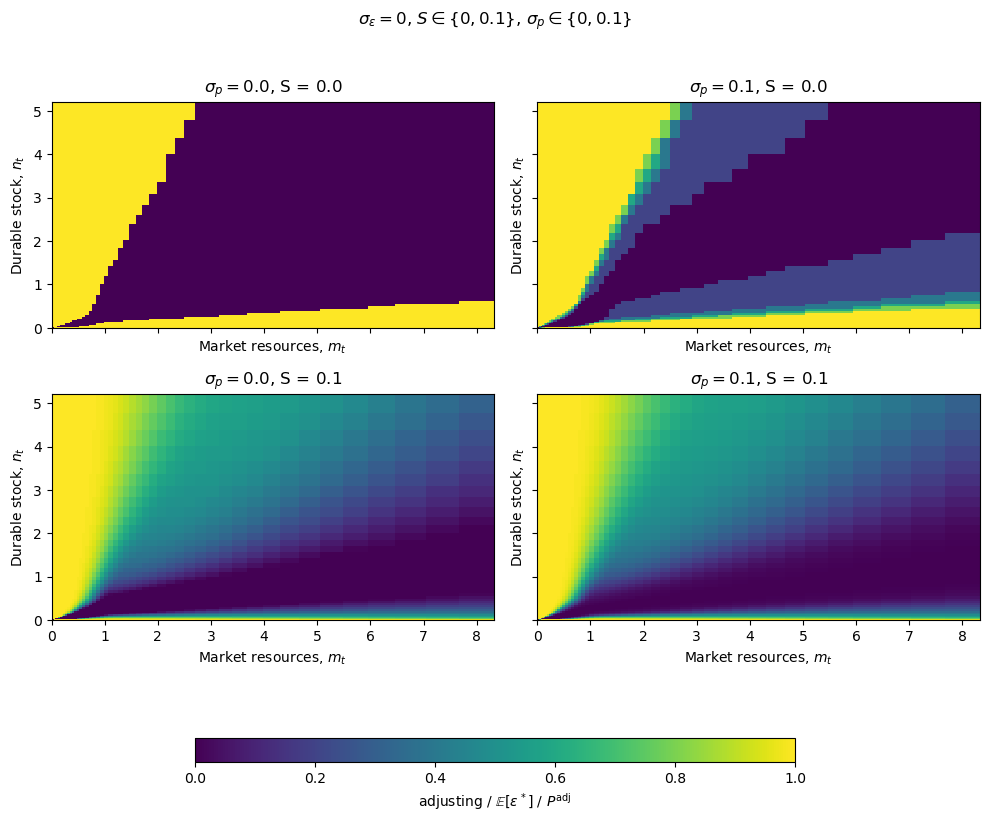

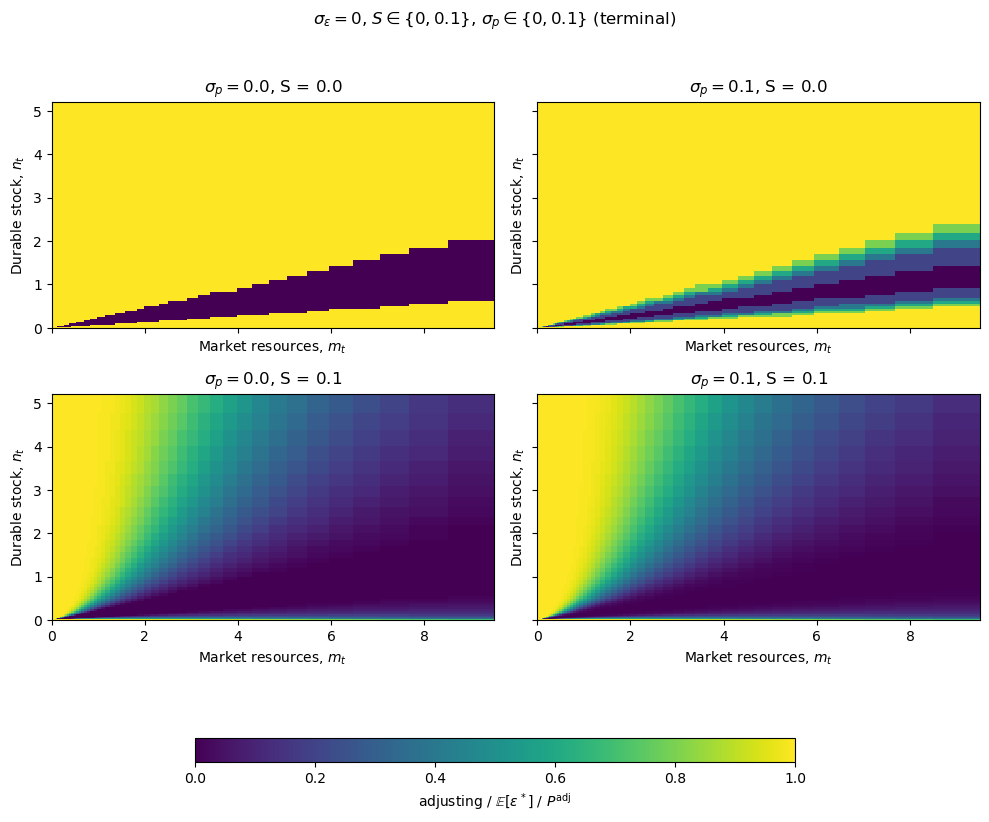

In [11]:
base_price_search = copy.deepcopy(durable_defaults)
base_price_search["sigma_eps"] = 0.0
base_price_search["SearchCost"] = 0.0

price_search_models = []
price_search_models.append(
        solve_variant(
            base_price_search,
            PriceShkStd=0.0,
            PriceShkCount=1,
            SearchCost = 0.0
        )
    )

price_search_models.append(
        solve_variant(
            base_price_search,
            PriceShkStd=0.1,
            PriceShkCount=5,
            SearchCost = 0.0
        )
    )

price_search_models.append(
        solve_variant(
            base_price_search,
            PriceShkStd=0.0,
            PriceShkCount=1,
            SearchCost = 0.1
        )
    )

price_search_models.append(
        solve_variant(
            base_price_search,
            PriceShkStd=0.1,
            PriceShkCount=5,
            SearchCost = 0.1
        )
    )


price_search_labels = ['$\\sigma_{p} = 0.0$, S = 0.0',
 '$\\sigma_{p} = 0.1$, S = 0.0',
 '$\\sigma_{p} = 0.0$, S = 0.1',
 '$\\sigma_{p} = 0.1$, S = 0.1']
 
title = r"$\sigma_{\varepsilon} = 0$, $S \in \{0, 0.1\}$, $\sigma_{p} \in \{0, 0.1\}$"
plot_adjuster_policies(price_search_models, price_search_labels, t, title, "PriceStd_Search")
plot_adjuster_mpcs(price_search_models, price_search_labels, t, title, "PriceStd_Search")
plot_combined_policies(price_search_models, price_search_labels, title, "PriceStd_Search")
plot_case_heatmaps(price_search_models, price_search_labels, t, "PriceStd_Search", suptitle=title)

